# scVI integration and cell annotation


## Imports

In [1]:
from __future__ import annotations
from pathlib import Path
import gc
from cap.figures import (
    CONDITION_ORDER,
    CONDITION_PALETTE,
    configure_figure_style,
    save_figure,
    save_umap_figure,
)
from cap.paths import get_paths
from cap.provenance import (
    sha256_file,
    validate_frozen_inputs,
    write_run_provenance,
)


In [2]:
import hashlib
import json
import os


In [3]:
from matplotlib.colors import to_hex
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D


In [4]:
from sklearn.decomposition import PCA
import anndata as ad
import matplotlib as mpl


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [6]:
import scanpy as sc
import scipy.sparse as sp
import scvi


In [7]:
import seaborn as sns
import session_info


## Paths and reference genes

In [8]:
# Use a new CAP_RUN_ID for each complete pipeline rerun.
paths = get_paths()
paths.validate_base_inputs()
validate_frozen_inputs(paths)


In [9]:
stage_dir = paths.ensure_stage("02_cell_annotation")


In [10]:
preprocessing_dir = paths.stage_dir("01_preprocessing")
paths.require_dir(preprocessing_dir, "01_preprocessing stage")


WindowsPath('D:/IdeaProjects/CAP_Submission/CAP_Data/runs/preprocessing_test_003/01_preprocessing')

In [11]:
cohort_file = paths.root / "config" / "cohort_release_2026-11-13.csv"


In [12]:
decision_file = paths.frozen_dir / "cell_annotation_decisions.json"
policy_file = paths.frozen_dir / "gene_policy.json"
celltypist_model_file = paths.celltypist_model_file


In [13]:
# Fixed gene annotations and gene sets, not cell labels or analysis results.
policy_sha256 = "c4213d53e2d3209312e7781c73ed20f660e0f256042956742693c0e0375926a6"
os.environ["RPY2_CFFI_MODE"] = "ABI"


In [14]:
paths.require_file(cohort_file, "frozen cohort release")
paths.require_file(decision_file, "frozen cell-annotation decisions")
paths.require_file(policy_file, "frozen gene policy")

with decision_file.open(encoding="utf-8") as handle:
    frozen_decisions = json.load(handle)

required_decision_keys = {
    "decision_timing",
    "run_reference_annotation",
    "excluded_patients",
    "cluster_labels",
    "low_quality_clusters",
}
missing_decision_keys = required_decision_keys.difference(frozen_decisions)
if missing_decision_keys:
    raise KeyError(
        f"Frozen decision file is missing: {sorted(missing_decision_keys)}"
    )

run_reference_annotation = frozen_decisions["run_reference_annotation"]
if type(run_reference_annotation) is not bool:
    raise TypeError("run_reference_annotation must be a frozen boolean decision")

if run_reference_annotation:
    paths.require_file(celltypist_model_file, "CellTypist reference model")

cohort_sha256 = sha256_file(cohort_file)
celltypist_model_sha256 = (
    sha256_file(celltypist_model_file) if run_reference_annotation else None
)


In [15]:
if stage_dir.resolve() == preprocessing_dir.resolve():
    raise ValueError("02_cell_annotation must be separate from 01_preprocessing.")
if any(stage_dir.iterdir()):
    raise FileExistsError(
        f"{stage_dir} is not empty. Use a fresh CAP_RUN_ID; "
        "existing stage outputs are immutable."
    )


In [16]:
head_dir = preprocessing_dir / "h5ad" / "head"
qc_input_dir = preprocessing_dir / "tables" / "by_sample"


In [17]:
save_dir = stage_dir / "h5ad"
model_dir = stage_dir / "models"
fig_dir = stage_dir / "figures"
df_dir = stage_dir / "tables"


In [18]:
for directory in (save_dir, model_dir, fig_dir, df_dir):
    directory.mkdir(parents=True, exist_ok=True)

write_run_provenance(paths, stage_dir)

input_checksums = {
    "cohort_release_2026-11-13.csv": cohort_sha256,
    "cell_annotation_decisions.json": sha256_file(decision_file),
    "gene_policy.json": sha256_file(policy_file),
    "frozen_inputs.json": sha256_file(paths.manifest_dir / "frozen_inputs.json"),
    "celltypist_model_file": celltypist_model_sha256,
}
(stage_dir / "input_checksums.json").write_text(
    json.dumps(input_checksums, indent=2) + "\n",
    encoding="utf-8",
)


487

In [19]:
def load_gene_policy(path=policy_file):
    path = Path(path)
    payload = path.read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    if digest != policy_sha256:
        raise ValueError(
            "Gene-policy checksum differs from the reviewed source snapshot"
        )
    policy = json.loads(payload)
    policy["sha256"] = digest
    return policy


In [20]:
gene_policy = load_gene_policy()


## Figure settings

The shared `cap.figures` configuration defines the publication style and SVG/PNG export behavior. UMAP exports rasterize dense point collections inside SVG files while retaining vector axes, labels, legends, and annotations.


In [21]:
configure_figure_style()


In [22]:
sc.settings.figdir = fig_dir
sc.settings.verbosity = 1
np.random.seed(0)


In [23]:
# Preserve aliases used before condition labels are standardised.
condition_palette = {
    "HER2": CONDITION_PALETTE["HER2+"],
    "HER2+": CONDITION_PALETTE["HER2+"],
    "TN": CONDITION_PALETTE["TN"],
    "ER": CONDITION_PALETTE["ER+"],
    "ER+": CONDITION_PALETTE["ER+"],
    "N2": CONDITION_PALETTE["N"],
    "N": CONDITION_PALETTE["N"],
}


In [24]:
condition_order = list(CONDITION_ORDER)
condition_rank = {condition: index for index, condition in enumerate(condition_order)}


In [25]:
# SVG font handling is defined by the shared figure configuration.


In [26]:
import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)


## Cohort and preprocessed libraries

The cohort table and post-QC count matrices come from the selected 000/001
folder. The study's explicit MH0114 exclusion is retained. No integrated atlas,
trained scVI model, cell-label table or historical exclusion table is loaded.

In [27]:
samples = pd.read_csv(cohort_file)


In [28]:
excluded_patients = frozen_decisions["excluded_patients"]


In [29]:
samples["include_before_patient_exclusion"] = samples["include"]


In [30]:
patient_exclusion = samples["patient"].isin(excluded_patients)
samples.loc[patient_exclusion, "include"] = False
samples.loc[patient_exclusion, "exclusion_reason"] = samples.loc[
    patient_exclusion, "patient"
].map(excluded_patients)


In [31]:
wanted = samples.loc[samples["include"], "sample_id"].tolist()
assert len(samples) == 69 and len(wanted) == (43 if excluded_patients else 45)
assert samples.loc[samples["include"], "patient"].nunique() == (41 if excluded_patients else 42)


In [32]:
missing_libraries = [
    sample for sample in wanted if not (head_dir / f"{sample}.h5ad").is_file()
]
if missing_libraries:
    raise FileNotFoundError(
        f"001 preprocessing outputs are missing for {len(missing_libraries)} libraries. "
        "Set head_dir to the retained 001 output folder, or generate them with 001 before running 002."
    )
qc_files = [qc_input_dir / sample_id / "qc_summary.csv" for sample_id in wanted]
missing_qc = [str(f) for f in qc_files if not f.is_file()]
assert qc_files, "No samples selected for QC summary"
assert not missing_qc, f"Missing 001 QC tables in the configured run: {missing_qc}"
print(f"{len(wanted)} samples expected")


43 samples expected


In [33]:
adatas = []


In [34]:
for sample_id in wanted:
    path = head_dir / f"{sample_id}.h5ad"
    assert path.exists(), f"001 output missing: {sample_id}"
    a = sc.read_h5ad(path)
    # Only post-QC libraries are valid inputs at this stage.
    derived_fields = {
        "scVI_leiden", "cl_annotation", "epithelial_candidate",
        "epithelial_primary", "epithelial_uncertain", "reference_cluster",
        "annotation_review_status", "annotation_review_subcluster",
        "celltypist_pal_label", "celltypist_pal_conf",
    }
    inherited_fields = derived_fields.intersection(a.obs.columns)
    if inherited_fields or "X_scVI" in a.obsm or "annotation_mapping" in a.uns:
        raise ValueError(f"Expected a 001 post-QC input, not an annotated/integrated object: {path}")
    a.obs["sample"] = sample_id
    adatas.append(a)


In [35]:
assert len(adatas) == len(wanted), f"loaded {len(adatas)}, expected {len(wanted)}"
print(f"{len(adatas)} loaded, {sum((a.n_obs for a in adatas)):,} cells")


43 loaded, 228,944 cells


In [36]:
deviance = pd.DataFrame({s: a.var["deviance"] for s, a in zip(wanted, adatas)})


## Concatenation and QC metrics

In [37]:
adata = ad.concat(
    adatas, join="inner", label="batch", keys=wanted, index_unique="-", merge="same"
)


In [38]:
# Each library has its own PCA basis; pooled embeddings are computed below.
adata.obsm.clear()
adata.obsp.clear()

In [39]:
adata.obs["condition"] = adata.obs["sample"].str.split("_").str[1].str.split("-").str[0]
adata.obs["patient"] = adata.obs["sample"].map(
    dict(zip(samples.sample_id, samples.patient))
)


In [40]:
assert not adata.obs["patient"].astype(str).isin(excluded_patients).any()
adata.uns["cohort_selection"] = {
    "excluded_patients": list(excluded_patients),
    "exclusion_reasons": dict(excluded_patients),
    "decision_timing": frozen_decisions["decision_timing"],
    "cohort": "donor-exclusion primary" if excluded_patients else "full-cohort sensitivity",
    "n_source_libraries": int(len(samples)),
    "n_selected_libraries": int(len(wanted)),
    "n_selected_patients": int(samples.loc[samples["include"], "patient"].nunique()),
}


In [41]:
samples.to_csv(df_dir / "cohort_samples.csv", index=False)


In [42]:
(df_dir / "cohort_selection.json").write_text(
    json.dumps(adata.uns["cohort_selection"], indent=2) + "\n"
)


427

In [43]:
def feature_identities(var, policy):
    """Assign frozen HGNC IDs by stable matrix IDs, without changing var_names."""
    if not var.index.is_unique or "gene_id" not in var:
        raise ValueError(
            "Unique feature names and original Ensembl gene_id values are required"
        )
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    canonical = {}
    for records in policy["symbols"].values():
        for record in records:
            if record["ensembl_id"]:
                canonical.setdefault(record["ensembl_id"], set()).add(record["hgnc_id"])
    values = []
    for identifier in ids:
        identity = policy["feature_hgnc_ids"].get(identifier)
        if identity is None:
            candidates = canonical.get(identifier, set())
            identity = next(iter(candidates)) if len(candidates) == 1 else ""
        values.append(identity)
    return pd.Series(values, index=var.index, name="hgnc_id")


In [44]:
def apply_gene_flags(adata, policy):
    """Replace broad QC prefixes with reviewed family memberships."""
    identity = feature_identities(adata.var, policy)
    audit = pd.DataFrame(
        {
            "feature_gene": adata.var_names.astype(str),
            "feature_id": adata.var["gene_id"].astype(str).to_numpy(),
            "hgnc_id": identity.to_numpy(),
        }
    )
    for flag in ["mt", "ribo", "hb"]:
        old = (
            adata.var[flag].astype(bool).to_numpy()
            if flag in adata.var
            else np.zeros(adata.n_vars, bool)
        )
        new = identity.isin(policy["families"][flag]).to_numpy()
        adata.var[flag] = new
        audit[flag + "_before"] = old
        audit[flag + "_after"] = new
    return audit


In [45]:
def refresh_ribosomal_qc(adata, layer="counts"):
    """Refresh the ribosomal diagnostic without changing cell-QC decisions."""
    matrix = adata.layers[layer]
    total = np.asarray(matrix.sum(axis=1)).ravel()
    ribosomal = np.asarray(
        matrix[:, adata.var["ribo"].to_numpy(bool)].sum(axis=1)
    ).ravel()
    adata.obs["total_counts_ribo"] = ribosomal
    adata.obs["log1p_total_counts_ribo"] = np.log1p(ribosomal)
    adata.obs["pct_counts_ribo"] = np.divide(
        100 * ribosomal, total, out=np.zeros_like(total, dtype=float), where=total > 0
    )


In [46]:
gene_flag_audit = apply_gene_flags(adata, gene_policy)


In [47]:
refresh_ribosomal_qc(adata)


In [48]:
gene_flag_audit.to_csv(df_dir / "atlas_gene_flags.csv", index=False)


In [49]:
d = adata.layers["counts"].data
assert np.allclose(d, np.round(d)), "counts layer is not integer"


In [50]:
del adatas
gc.collect()


43

## Gene filtering and variable features

In [51]:
sc.pp.filter_genes(adata, min_cells=3)
print("genes after filter:", adata.n_vars)


genes after filter: 28502


In [52]:
for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    assert g in adata.var_names, f"{g} was filtered out"


In [53]:
adata.var["binomial_deviance"] = deviance.reindex(adata.var_names).max(axis=1)
assert adata.var["binomial_deviance"].notna().all()


In [54]:
def resolve_signature(genes, var, policy):
    """Return unique available feature names and a complete source-member audit.

    Exact original features remain preferred when consistent with the frozen
    identity. Otherwise a unique stable-ID/HGNC match is required. Ambiguities
    stop the run; absent source members remain explicit audit rows.
    """
    identities = feature_identities(var, policy)
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    rows, selected = ([], [])
    for gene in dict.fromkeys(map(str, genes)):
        candidates = policy["symbols"].get(gene, [])
        hgnc_ids = {r["hgnc_id"] for r in candidates}
        expected_ids = {r["ensembl_id"] for r in candidates if r["ensembl_id"]}
        chosen, method = (None, "unavailable")
        if gene in var.index:
            identity = identities.loc[gene]
            if hgnc_ids and identity and (identity not in hgnc_ids):
                raise ValueError(
                    f"Exact feature conflicts with source identity: {gene}"
                )
            chosen, method = (gene, "exact_original_feature")
        else:
            direct = var.index[ids.isin(expected_ids)]
            matches = direct if len(direct) else var.index[identities.isin(hgnc_ids)]
            if len(matches) > 1:
                raise ValueError(
                    f"Ambiguous source-to-feature mapping: {gene}: {list(matches)}"
                )
            if len(matches) == 1:
                chosen = str(matches[0])
                method = (
                    "verified_Ensembl_ID" if len(direct) else "frozen_HGNC_identity"
                )
        duplicate = chosen is not None and chosen in selected
        if chosen is not None and (not duplicate):
            selected.append(chosen)
        rows.append(
            {
                "source_gene": gene,
                "feature_gene": chosen or "",
                "feature_id": str(ids.loc[chosen]) if chosen is not None else "",
                "hgnc_id": identities.loc[chosen] if chosen is not None else "",
                "method": (
                    "duplicate_feature_not_double_weighted" if duplicate else method
                ),
                "used": chosen is not None and (not duplicate),
            }
        )
    return (selected, pd.DataFrame(rows))


In [55]:
def cell_cycle_genes(var, policy):
    s_genes, s_audit = resolve_signature(policy["cell_cycle"]["s.genes"], var, policy)
    g2m_genes, g_audit = resolve_signature(
        policy["cell_cycle"]["g2m.genes"], var, policy
    )
    return (
        s_genes,
        g2m_genes,
        pd.concat(
            [s_audit.assign(phase="S"), g_audit.assign(phase="G2M")], ignore_index=True
        ),
    )


In [56]:
s_genes, g2m_genes, cycle_gene_audit = cell_cycle_genes(adata.var, gene_policy)


In [57]:
def stamp_gene_policy(adata, policy, stage, cell_cycle_scored=None):
    previous = dict(adata.uns.get("gene_policy", {}))
    previous.update(
        {"version": policy["version"], "sha256": policy["sha256"], "stage": stage}
    )
    if cell_cycle_scored is not None:
        previous["cell_cycle_scored"] = bool(cell_cycle_scored)
    adata.uns["gene_policy"] = previous


In [58]:
def score_cell_cycle_by_sample(adata, policy, sample_key="sample", seed=0):
    """Refresh phase on post-QC raw counts, normalised per cell, one library at a time."""
    import anndata as ad
    import scanpy as sc

    s_genes, g2m_genes, audit = cell_cycle_genes(adata.var, policy)
    if not audit.used.all():
        raise ValueError(
            "The reviewed 43/54 cell-cycle panel is incomplete in this input"
        )
    matrix = adata.layers["counts"]
    for sample in adata.obs[sample_key].astype(str).unique():
        mask = adata.obs[sample_key].astype(str).eq(sample).to_numpy()
        tmp = ad.AnnData(
            X=matrix[mask].copy(),
            obs=pd.DataFrame(index=adata.obs_names[mask]),
            var=adata.var.copy(),
        )
        sc.pp.normalize_total(tmp, target_sum=10000.0)
        sc.pp.log1p(tmp)
        sc.tl.score_genes_cell_cycle(
            tmp, s_genes=s_genes, g2m_genes=g2m_genes, random_state=seed, use_raw=False
        )
        for column in ["S_score", "G2M_score"]:
            adata.obs.loc[tmp.obs_names, column] = tmp.obs[column].to_numpy(float)
        if "phase" not in adata.obs:
            adata.obs["phase"] = ""
        else:
            adata.obs["phase"] = adata.obs["phase"].astype(object)
        adata.obs.loc[tmp.obs_names, "phase"] = tmp.obs.phase.astype(str).to_numpy()
        del tmp
    adata.obs["phase"] = pd.Categorical(
        adata.obs["phase"], categories=["G1", "S", "G2M"]
    )
    stamp_gene_policy(adata, policy, "atlas", cell_cycle_scored=True)
    return audit


In [59]:
cycle_gene_audit = score_cell_cycle_by_sample(adata, gene_policy, seed=0)


In [60]:
cycle_gene_audit.to_csv(df_dir / "atlas_cell_cycle_genes.csv", index=False)


In [61]:
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()
exclude |= adata.var_names.isin(s_genes + g2m_genes)
exclude |= (
    feature_identities(adata.var, gene_policy)
    .isin(gene_policy["families"]["immunoglobulin"])
    .to_numpy()
)


In [62]:
ranked = adata.var.loc[~exclude, "binomial_deviance"].sort_values(ascending=False)


In [63]:
adata.var["highly_variable"] = adata.var_names.isin(ranked.index[:2000])
assert adata.var["highly_variable"].sum() == 2000


## Structure before integration

In [64]:
adata_pre = adata[:, adata.var["highly_variable"]].copy()
adata_pre.X = adata_pre.layers["log1p"]
print(f"Shape after HVG subset: {adata_pre.shape}")


Shape after HVG subset: (228944, 2000)


In [65]:
sc.pp.scale(adata_pre, max_value=10, zero_center=False)


In [66]:
sc.tl.pca(adata_pre, n_comps=20, zero_center=False, random_state=0)


In [67]:
sc.pp.neighbors(adata_pre, use_rep="X_pca", n_pcs=20, n_neighbors=15, random_state=0)


In [68]:
sc.tl.umap(adata_pre, random_state=0)


In [69]:
assert len(qc_files) == len(wanted), "QC preflight does not match selected libraries"


In [70]:
qc = pd.concat([pd.read_csv(path) for path in qc_files], ignore_index=True)

if "sample_id" in qc.columns and "sample" not in qc.columns:
    qc = qc.rename(columns={"sample_id": "sample"})

if ("miqc_mt_cutoff" in qc.columns and "max_retained_pct_mt" not in qc.columns):
    qc = qc.rename(columns={"miqc_mt_cutoff": "max_retained_pct_mt"})

assert qc["sample"].is_unique
assert set(qc["sample"]) == set(wanted), (
    "QC tables do not match the selected libraries"
)

In [71]:
qc = qc.sort_values(["condition", "sample"]).reset_index(drop=True)


In [72]:
qc.to_csv(df_dir / "qc_summary.csv", index=False)


In [73]:
print(
    qc.groupby("condition")[["n_cells_final", "max_retained_pct_mt", "pct_doublets"]]
    .agg(["count", "sum", "median"])
    .round(1)
    .to_string()
)


          n_cells_final                max_retained_pct_mt               pct_doublets              
                  count    sum  median               count    sum median        count    sum median
condition                                                                                          
ER                   17  88870  5398.0                  17  287.9   12.9           17  141.9    8.3
HER2                  6  38460  4811.5                   6  127.6   19.1            6   52.2    8.0
N                    13  51222  4062.0                  13  194.7   10.7           13   89.0    6.9
TN                    7  50392  5088.0                   7  135.8   12.1            7   67.6    9.2


In [74]:
display(qc)


,sample,condition,n_cells_final,n_genes,max_retained_pct_mt,pct_doublets,pc1_depth_corr,median_counts,median_genes,miqc_converged,mt_filter_path,mt_floor
0,GSM4909295_ER-AH0319,ER,2869,33538,11.4,5.8,-0.701,2145,868,True,miqc,10
1,GSM4909296_ER-MH0001,ER,6277,33538,10.0,10.4,-0.609,1340,533,True,miqc,10
2,GSM4909297_ER-MH0125,ER,6421,33538,10.0,10.8,0.695,957,522,True,miqc,10
3,GSM4909298_ER-PM0360,ER,5534,33538,18.2,7.5,0.713,1218,539,True,miqc,10
4,GSM4909300_ER-MH0032,ER,1232,33538,11.1,3.9,0.572,2195,866,True,miqc,10
5,GSM4909301_ER-MH0042,ER,4716,33538,10.0,8.3,0.487,1664,765,True,miqc,10
6,GSM4909302_ER-MH0025,ER,8202,33538,11.1,11.6,-0.573,1719,805,True,miqc,10
7,GSM4909303_ER-MH0151,ER,2592,33538,28.6,5.7,0.731,2205,962,True,miqc,10
8,GSM4909304_ER-MH0163,ER,5918,33538,31.3,8.4,0.716,3959,1429,True,miqc,10
9,GSM4909305_ER-MH0029-7C,ER,2926,33538,15.7,6.2,0.552,3996,1523,True,miqc,10


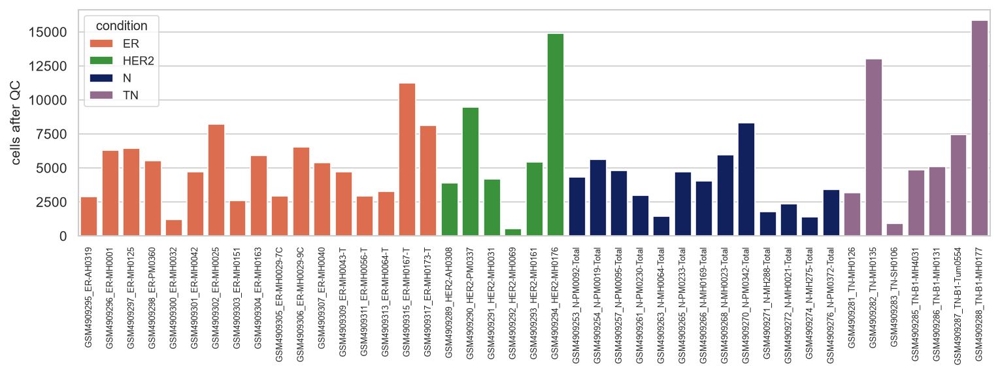

In [75]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(
    data=qc,
    x="sample",
    y="n_cells_final",
    hue="condition",
    palette=condition_palette,
    dodge=False,
    ax=ax,
)
ax.set(xlabel="", ylabel="cells after QC")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, fig_dir / "cells_per_sample", close=False, overwrite=False)
plt.show()


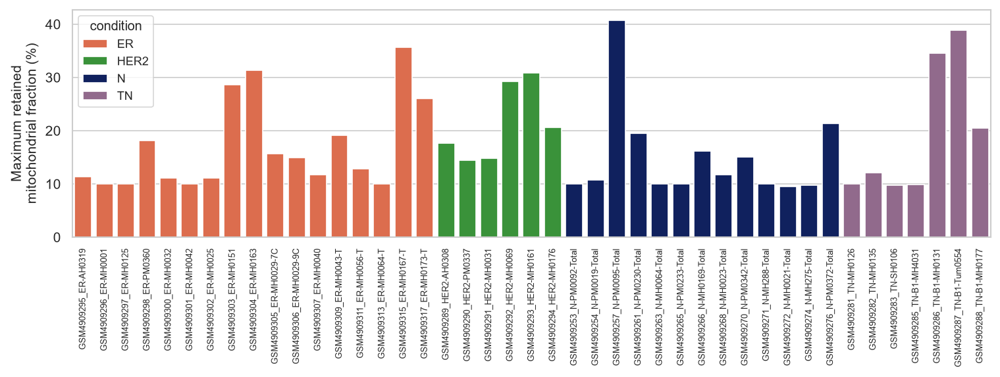

In [76]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(
    data=qc,
    x="sample",
    y="max_retained_pct_mt",
    hue="condition",
    palette=condition_palette,
    dodge=False,
    ax=ax,
)
ax.set(xlabel="", ylabel="Maximum retained\nmitochondrial fraction (%)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, fig_dir / "maximum_retained_mitochondrial_fraction_per_sample", close=False, overwrite=False)
plt.show()


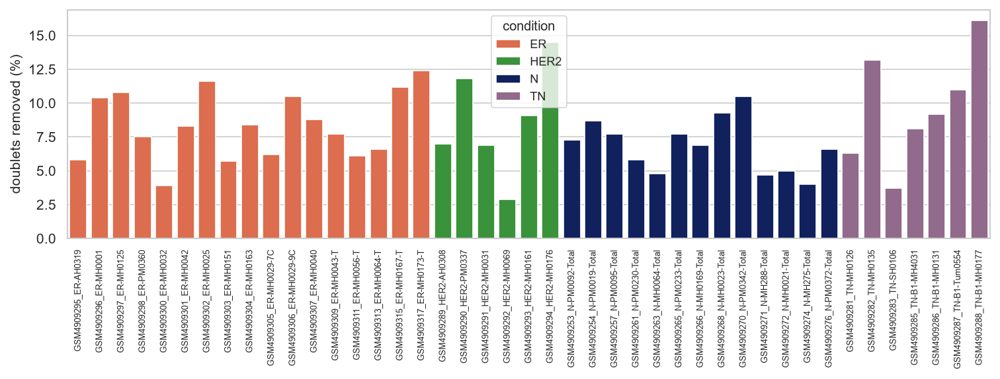

In [77]:
fig, ax = plt.subplots(figsize=(12, 3))
sns.barplot(
    data=qc,
    x="sample",
    y="pct_doublets",
    hue="condition",
    palette=condition_palette,
    dodge=False,
    ax=ax,
)
ax.set(xlabel="", ylabel="doublets removed (%)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, fig_dir / "doublets_per_sample", close=False, overwrite=False)
plt.show()


C:\Users\vonal\AppData\Local\Temp\ipykernel_16728\3952294991.py:2: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


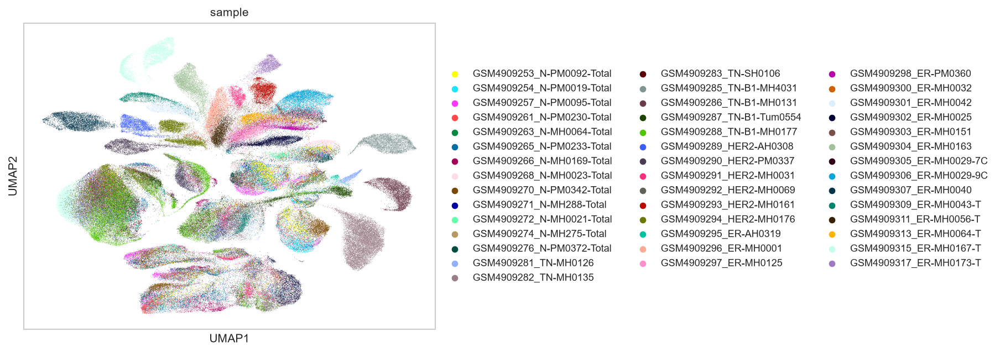

In [78]:
sc.pl.umap(adata_pre, color="sample", show=False)
plt.tight_layout()
save_umap_figure(plt.gcf(), fig_dir / "umap_before_integration", close=False, overwrite=False)
plt.show()


In [79]:
del adata_pre
gc.collect()


32746

## scVI integration

In [80]:
assert not (
    feature_identities(adata.var, gene_policy).isin(
        gene_policy["families"]["immunoglobulin"]
    )
    & adata.var["highly_variable"]
).any()


In [81]:
adata_scvi = adata[:, adata.var["highly_variable"]].copy()


In [82]:
scvi.settings.seed = 0
scvi.settings.num_workers = 4


Seed set to 0


In [83]:
scvi.model.SCVI.setup_anndata(adata_scvi, layer="counts", batch_key="sample")


To Train a new model

In [84]:
model = scvi.model.SCVI(adata_scvi, n_latent=30, n_layers=2, gene_likelihood="nb")


In [85]:
model.train(
    max_epochs=400,
    accelerator="cpu",
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=0.5,
)
print(f"stopped after {model.history['elbo_train'].shape[0]} epochs")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider inc

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 20 records. Best score: 1380.270. Signaling Trainer to stop.
stopped after 283 epochs


In [87]:
model.save(str(model_dir), overwrite=False)

In [88]:
model.history["elbo_train"].to_csv(df_dir / "scvi_atlas_history.csv")

In [89]:
adata_scvi.obsm["X_scVI"] = model.get_latent_representation()
assert not np.isnan(adata_scvi.obsm["X_scVI"]).any()

In [90]:
del model
gc.collect()

485

In [91]:
adata.obsm["X_scVI"] = adata_scvi.obsm["X_scVI"]

In [92]:
pd.Series(adata_scvi.var_names.astype(str)).to_csv(
    model_dir / "var_names.csv",
    index=False,
    header=False,
)

In [93]:
del adata_scvi
gc.collect()

0

## Neighbours, clusters and UMAP

In [94]:
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=30, random_state=0)


In [95]:
sc.tl.leiden(adata,
             key_added="scVI_leiden", resolution=1,
    flavor="igraph", n_iterations=2, directed=False, random_state=0)


In [96]:
sc.tl.umap(adata, random_state=0)


In [97]:
r = np.corrcoef(adata.obsm["X_scVI"][:, 0], adata.obs["total_counts"])[0, 1]
print(f"scVI latent dim 1 vs total counts: r = {r:+.2f}")


scVI latent dim 1 vs total counts: r = -0.06


In [98]:
pca = PCA(n_components=2, random_state=0).fit_transform(adata.obsm["X_scVI"])


C:\Users\vonal\AppData\Local\Temp\ipykernel_16728\3419947116.py:20: UserWarning: scvi_latent_pca.svg is 76.5 MB. For dense scatter plots, call save_figure(..., rasterize_points=True).
  save_figure(fig, fig_dir / "scvi_latent_pca", close=False, overwrite=False)
D:\Conda\envs\cap-rerun\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


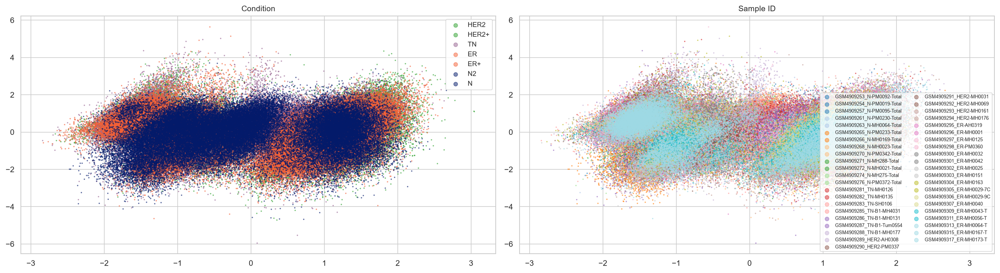

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
conditions = adata.obs["condition"].astype("category")
for cond, color in condition_palette.items():
    mask = conditions == cond
    axes[0].scatter(pca[mask, 0], pca[mask, 1], s=1, label=cond, color=color, alpha=0.5)
axes[0].set_title("Condition")
axes[0].legend(markerscale=5)
patients = adata.obs["sample"].astype("category")
colors = plt.cm.tab20(np.linspace(0, 1, len(patients.cat.categories)))
for i, pat in enumerate(patients.cat.categories):
    mask = patients == pat
    axes[1].scatter(
        pca[mask, 0], pca[mask, 1], s=1, label=pat, color=colors[i], alpha=0.5
    )
axes[1].set_title("Sample ID")
axes[1].legend(markerscale=5, fontsize=6, ncol=2)
del pca
gc.collect()
plt.tight_layout()
save_figure(fig, fig_dir / "scvi_latent_pca", close=False, overwrite=False)
plt.show()


In [100]:
conn = adata.obsp["connectivities"].tocsr()
codes = adata.obs["sample"].astype("category").cat.codes.to_numpy()
same = codes[conn.indices] == np.repeat(codes, np.diff(conn.indptr))


In [101]:
n_nb = np.maximum(np.diff(conn.indptr), 1)
frac_same = np.add.reduceat(same, conn.indptr[:-1]) / n_nb


In [102]:
p = adata.obs["sample"].value_counts(normalize=True).to_numpy()
expected = (p**2).sum()


In [103]:
print(f"neighbours from the same sample : {frac_same.mean():.3f}")
print(f"expected if perfectly mixed     : {expected:.3f}")
print(f"ratio                           : {frac_same.mean() / expected:.1f}x")


neighbours from the same sample : 0.409
expected if perfectly mixed     : 0.033
ratio                           : 12.4x


In [104]:
adata.write_h5ad(save_dir / "project_integrated.h5ad", compression="gzip")


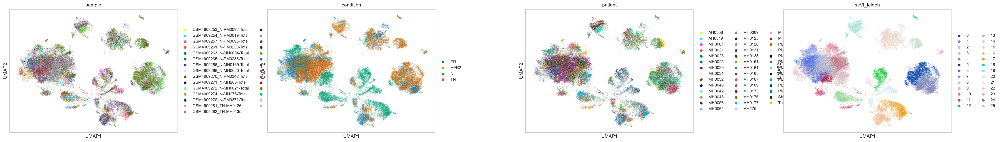

In [105]:
sc.pl.umap(
    adata,
    color=["sample", "condition", "patient", "scVI_leiden"],
    wspace=0.4,
    show=False,
)
save_umap_figure(plt.gcf(), fig_dir / "umap_sample_condition_patient_leiden", close=False, overwrite=False)
plt.show()


## Specimen labels

In [106]:
adata.obs["condition"] = adata.obs["condition"].str.replace("^ER$", "ER+", regex=True)
adata.obs["condition"] = adata.obs["condition"].str.replace(
    "^HER2$", "HER2+", regex=True
)
adata.obs["condition"] = pd.Categorical(
    adata.obs["condition"], categories=condition_order, ordered=True
)

In [107]:
unexpected = set(adata.obs["condition"].unique()) - set(condition_order)
assert not unexpected, f"Unexpected conditions: {unexpected}"

In [108]:
adata.obs["sample_short"] = (
    adata.obs["sample"].astype(str)
    .str.strip().str.replace(".h5ad", "", regex=False).str.split("_", n=1).str[-1]
    .str.replace("^(TN|ER|HER2|N)-", "", regex=True).astype("category"))

## Cluster markers

In [109]:
adata.layers["lognorm"] = adata.layers["log1p"]


In [110]:
sc.tl.rank_genes_groups(
    adata, groupby="scVI_leiden", layer="lognorm", method="wilcoxon")


D:\Conda\envs\cap-rerun\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
D:\Conda\envs\cap-rerun\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
D:\Conda\envs\cap-rerun\Lib\site-packages\scanpy\tools\_rank_genes_groups.py:463: PerformanceWarning: DataFrame is highly fragmented.  This is usually the 

In [111]:
degs = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(60)


In [112]:
degs.to_csv(df_dir / "cluster_degs.csv", index=False)
display(degs)


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,B2M,CCL5,KRT19,HMGA1,STMN1,GAPDH,KRT19,SAT1,MUCL1,MGP,...,COL1A2,TNFAIP6,JCHAIN,SSR4,IGFBP7,IGFBP7,ACP5,TPSAB1,COX6C,TFPI
1,BTG1,B2M,KRT8,ALDH1A3,PCLAF,NDRG1,COX6C,AZGP1,MT-CO3,XBP1,...,COL1A1,GEM,GZMB,MZB1,C11orf96,HSPG2,CST3,TPSB2,MGP,AKAP12
2,TMSB4X,NKG7,KRT18,MMP7,H2AFZ,PERP,RPL13A,KRT7,CRISP3,AZGP1,...,COL3A1,CTSL,PLAC8,IGKC,MT2A,A2M,CTSK,CPA3,RAMP1,SQSTM1
3,HLA-A,CD52,COX6C,SAA1,CKS1B,LDHA,RPS18,KRT18,TSPAN1,STC2,...,LUM,DCN,CD74,IGHG1,MT1A,SPARC,SPP1,SRGN,FABP3,HMOX1
4,CD3D,TMSB4X,FXYD3,KRT7,HMGB2,PGK1,RPL41,AREG,SCGB2A2,ANKRD30A,...,SPARC,ANXA5,TCF4,IGHG3,CALD1,IFITM3,RGS10,RGS1,PTP4A2,NEAT1
5,RPS27,HCST,PPDPF,MGST1,HMGN2,MAL2,PPDPF,TACSTD2,SCGB1D2,EFHD1,...,DCN,APOD,IRF7,FKBP11,AKAP12,RAMP2,TYROBP,HPGDS,H2AFJ,SOD2
6,HLA-B,BTG1,TRPS1,TACSTD2,PTMA,S100A10,XBP1,MYL6,MUC1,ADIRF,...,COL6A3,CXCL2,HLA-DRA,IGHG4,TAGLN,PECAM1,NPC2,MS4A2,ADIRF,ANGPT2
7,CD52,HLA-B,SPINT2,SOD2,TUBB,CD24,RPS15,ANXA2,CYP4X1,MAGED2,...,LGALS1,MEG3,IRF8,DERL3,ADAMTS4,GNG11,MMP9,CD69,CRIP1,VIM
8,LTB,CCL4,MARCKSL1,CD59,TUBA1B,KRT19,AZGP1,MYL12B,P4HB,ELF3,...,FN1,SOD2,ALOX5AP,HERPUD1,EPAS1,EGFL7,GRN,LTC4S,RPS4X,PDPN
9,CXCR4,GZMA,CD9,S100A6,UBE2C,CSTB,RPL23A,MGST1,MT-ND1,KRT18,...,COL6A1,HSP90AB1,HERPUD1,JCHAIN,MAP1B,VWF,ATP6V0E1,FCER1G,TBC1D9,CD59


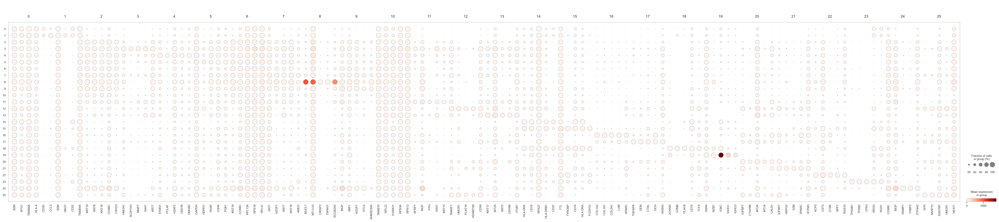

In [113]:
sc.pl.rank_genes_groups_dotplot(
    adata, n_genes=5, swap_axes=False, dendrogram=False, show=False)
save_figure(plt.gcf(), fig_dir / "dotplot_cluster_degs", close=False, overwrite=False)
plt.show()


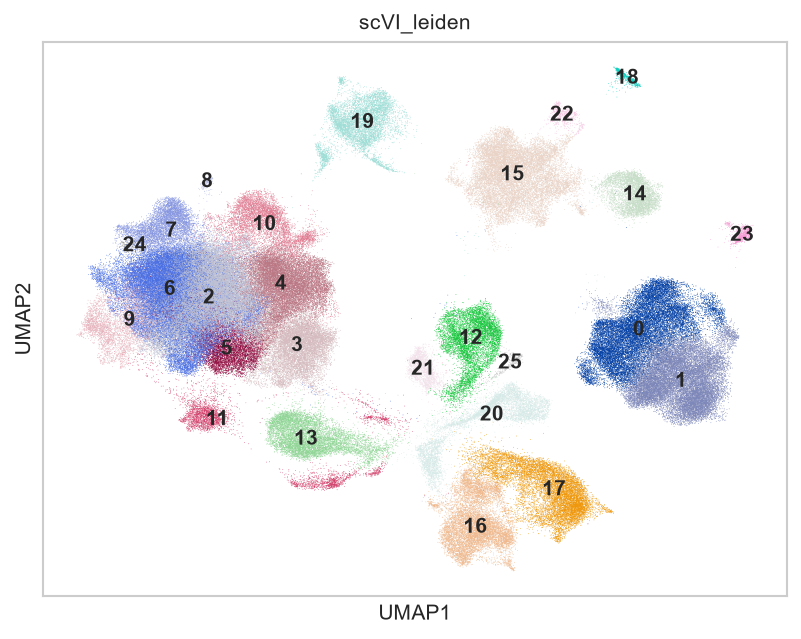

In [114]:
sc.pl.umap(adata, color="scVI_leiden", legend_loc="on data", show=False)
save_umap_figure(plt.gcf(), fig_dir / "umap_cluster_numbers", close=False, overwrite=False)
plt.show()


## Lineage markers and cluster QC

In [115]:
broad_markers = {
    "T Cells": ["PTPRC", "CD3D", "CD3E", "TRAC"],
    "NK/T Cells": ["NKG7", "GNLY", "KLRD1", "KLRF1"],
    "B Cells": ["CD79A", "CD74", "MS4A1"],
    "Macrophages": ["CD68", "CD14", "ITGAM"],
    "Fibroblasts": ["COL1A1", "CXCL12", "MYL9"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHG1"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],
    "Mast Cells": ["KIT", "CPA3", "TPSAB1"],
    "Dendritic Cells": ["ITGAX", "HLA-DRA", "CD83"],
    "Epithelial Cells": ["EPCAM", "KRT19", "KRT18"],
    "Basal": ["KRT14", "KRT17", "OXTR"],
}


In [116]:
broad_markers_in_data = {
    cell_type: [gene for gene in genes if gene in adata.var_names]
    for cell_type, genes in broad_markers.items()
}


In [117]:
detailed_markers = {
    "T cells": ["PTPRC", "CD3D", "CD3E", "CD3G", "TRAC", "IL7R", "CD8A"],
    "NK cells": ["KLRF1", "NCR1", "FCER1G", "TYROBP", "NKG7", "GNLY", "KLRD1"],
    "B cells": ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Plasma cells": ["MZB1", "JCHAIN", "IGHG1", "XBP1", "DERL3"],
    "Macrophages": ["CD68", "CD14", "ITGAM", "LYZ", "AIF1", "CSF1R"],
    "SPP1+ macrophages": ["SPP1", "ACP5", "MMP9", "CTSK"],
    "Dendritic cells": ["ITGAX", "CD1C", "CLEC9A", "CD83"],
    "pDC": ["IRF7", "IRF8", "TCF4", "GZMB", "LILRA4", "PLAC8"],
    "Mast cells": ["KIT", "CPA3", "TPSAB1", "TPSB2", "MS4A2"],
    "Fibroblasts": ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "PDGFRA"],
    "Perivascular": ["ACTA2", "RGS5", "PDGFRB", "MYH11", "TAGLN"],
    "Endothelial": ["PECAM1", "VWF", "CDH5", "CLDN5"],
    "Lymphatic": ["CCL21", "PDPN", "PROX1", "LYVE1"],
    "Epithelial": ["EPCAM", "KRT8", "KRT18", "KRT19"],
    "Basal": ["KRT14", "KRT5", "KRT17", "TP63", "MYLK", "OXTR"],
    "Luminal progenitor": ["ALDH1A3", "KIT", "ELF5", "SLPI", "LTF", "KRT15"],
    "Mature luminal": ["ESR1", "PGR", "FOXA1", "ANKRD30A", "AREG", "TFF1", "GATA3"],
    "Ciliated": ["FOXJ1", "TPPP3", "CAPS", "FAM183A", "RSPH1", "PIFO"],
    "Cycling": ["MKI67", "TOP2A", "CCNB1"],
}


In [118]:
available = {k: [g for g in v if g in adata.var_names] for k, v in detailed_markers.items()}
missing = {
    k: [g for g in v if g not in adata.var_names] for k, v in detailed_markers.items()
}
print("missing:", {k: v for k, v in missing.items() if v})


missing: {}


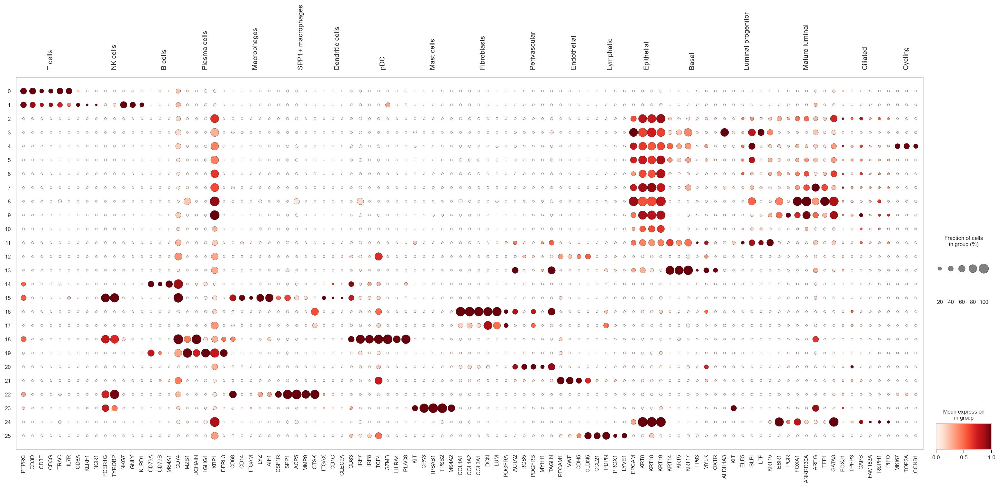

In [119]:
sc.pl.dotplot(
    adata,
    available,
    groupby="scVI_leiden",
    layer="log1p",
    standard_scale="var",
    smallest_dot=10,
    dendrogram=False,
    figsize=[26, 10],
    show=False,
)
save_figure(plt.gcf(), fig_dir / "dotplot_markers_all", close=False, overwrite=False)
plt.show()


In [120]:
print(
    adata.obs.groupby("scVI_leiden")[
        ["pct_counts_mt", "pct_counts_ribo", "n_genes_by_counts"]
    ]
    .median()
    .round(1)
    .to_string()
)


             pct_counts_mt  pct_counts_ribo  n_genes_by_counts
scVI_leiden                                                   
0                      7.2             26.9              502.0
1                      9.1             22.1              462.0
2                      6.6             25.7             1622.0
3                      5.0             31.3             2630.0
4                      5.8             22.8             2221.0
5                      4.6             27.6             1775.0
6                      6.9             28.8             1245.0
7                      4.1             18.4             1849.0
8                     19.0             11.9             4043.0
9                      6.6             23.7             1623.5
10                     4.0             31.8              510.0
11                     5.3             30.4             1161.5
12                     2.8             22.0             1315.0
13                     2.7             25.5            

C:\Users\vonal\AppData\Local\Temp\ipykernel_16728\3687430261.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("scVI_leiden")[


In [121]:
b_plasma_cts = ['T Cells', 'B Cells', 'Macrophages', 'Fibroblasts', 'Plasma Cells', 'Endothelial Cells', 'Mast Cells', 'Dendritic Cells', 'NK/T Cells']


In [122]:
b_plasma_markers = {
    ct: [m for m in ct_markers if m in adata.var.index]
    for ct, ct_markers in broad_markers_in_data.items()
    if ct in b_plasma_cts
}


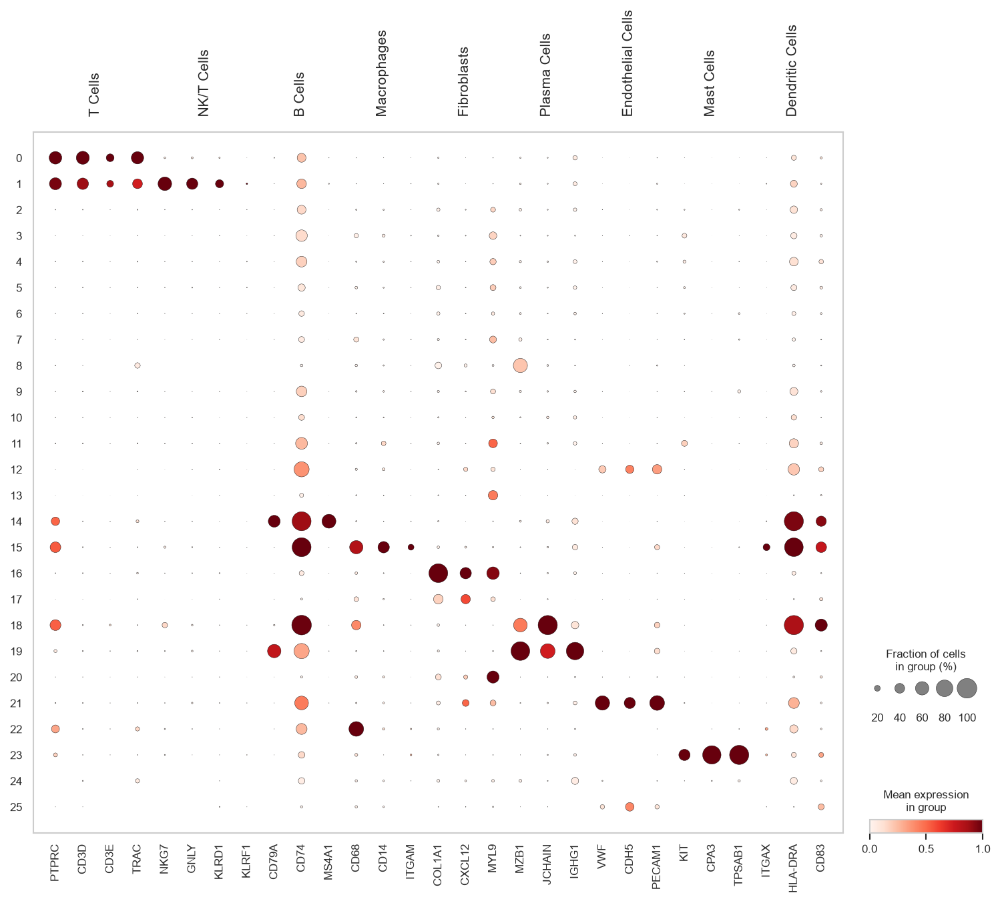

In [123]:
sc.pl.dotplot(
    adata,
    groupby="scVI_leiden",
    var_names=b_plasma_markers,
    layer="log1p",
    standard_scale="var",
    show=False,
)
save_figure(plt.gcf(), fig_dir / "dotplot_broad_lineages", close=False, overwrite=False)
plt.show()


In [124]:
marker_genes = {
    "T Cells": ["PTPRC", "CD3D", "CD3E", "TRAC"],
    "NK/T Cells": ["NKG7", "GNLY", "KLRD1", "KLRF1"],
    "B Cells": ["CD79A", "MS4A1", "CD74"],
    "Plasma Cells": ["MZB1", "JCHAIN", "IGHG1"],
    "Macrophages": ["CD68", "CD14", "ITGAM"],
    "Dendritic Cells": ["ITGAX", "HLA-DRA", "CD83"],
    "Mast Cells": ["KIT", "CPA3", "TPSAB1"],
    "Fibroblasts": ["COL1A1", "CXCL12", "MYL9"],
    "Endothelial Cells": ["VWF", "CDH5", "PECAM1"],
    "Epithelial Cells": ["EPCAM", "KRT19", "KRT18"],
    "Basal": ["KRT14", "KRT17", "OXTR"],
}


## Reference annotation

Supporting predictions use the original Ensembl IDs in `adata.var["gene_id"]`.
The supplied reference contains six epithelial/stromal classes and no immune
classes. Manual annotation uses cluster markers, differential expression and
QC alongside the reference predictions.


In [125]:
# Reference-annotation setting is loaded from the frozen decision file.


In [126]:
if run_reference_annotation:
    adata_norm = ad.AnnData(
        X=adata.layers["counts"].copy(), obs=adata.obs.copy(), var=adata.var.copy()
    )
    if not sp.issparse(adata_norm.X):
        adata_norm.X = sp.csr_matrix(adata_norm.X)
    elif not isinstance(adata_norm.X, sp.csr_matrix):
        adata_norm.X = adata_norm.X.tocsr()
    sc.pp.normalize_total(adata_norm, target_sum=10000.0)


In [127]:
if run_reference_annotation:
    sc.pp.log1p(adata_norm)
    import gc
    gc.collect()


In [128]:
if run_reference_annotation:
    # Preserve the original ID attached to each expression feature.
    gene_ids = adata_norm.var["gene_id"].astype("string")
    assert gene_ids.notna().all(), "Missing original gene IDs."
    assert gene_ids.is_unique, "Original gene IDs must be unique."
    assert gene_ids.str.fullmatch(r"ENSG[0-9]+").all(), "Expected unversioned Ensembl gene IDs."
    adata_norm.var["ensembl_id"] = gene_ids.astype(str)


In [129]:
if run_reference_annotation:
    n_mapped = adata_norm.var["ensembl_id"].notna().sum()
    print(f"mapped {n_mapped:,} / {adata_norm.n_vars:,} genes to Ensembl IDs")


mapped 28,502 / 28,502 genes to Ensembl IDs


In [130]:
if run_reference_annotation:
    import celltypist
    from celltypist import models
    mask = adata_norm.var["ensembl_id"].notna()


D:\Conda\envs\cap-rerun\Lib\site-packages\celltypist\classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


In [131]:
if run_reference_annotation:
    adata_pal = adata_norm[:, mask].copy()
    adata_pal.var_names = adata_pal.var["ensembl_id"].astype(str)
    pred_pal = celltypist.annotate(
        adata_pal,
        model=models.Model.load(str(celltypist_model_file)),
        majority_voting=False,
    )


🔬 Input data has 228944 cells and 28502 genes
🔗 Matching reference genes in the model
🧬 1396 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


In [132]:
if run_reference_annotation:
    del adata_pal
    gc.collect()
    del adata_norm


In [133]:
if run_reference_annotation:
    # Assign predictions only after checking the cell order.
    assert pred_pal.predicted_labels.index.equals(adata.obs_names)
    adata.obs["celltypist_pal_label"] = pred_pal.predicted_labels[
        "predicted_labels"
    ].values
    adata.obs["celltypist_pal_conf"] = pred_pal.probability_matrix.max(axis=1).values


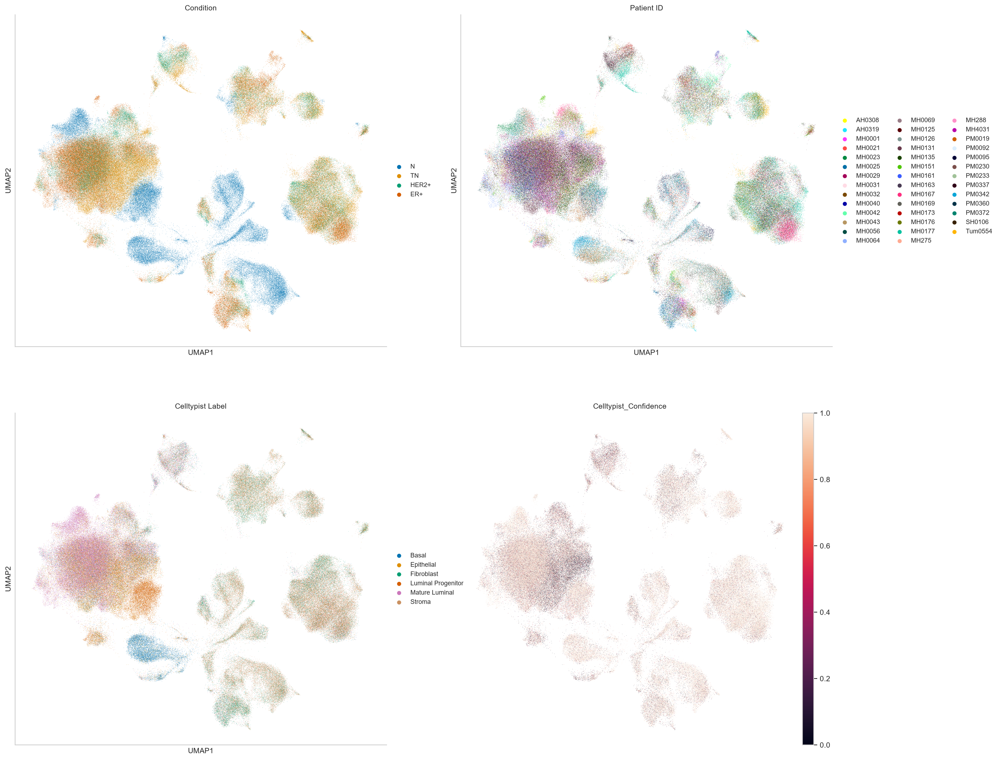

In [134]:
if run_reference_annotation:
    fig, axes = plt.subplots(2, 2, figsize=(20, 18))
    axes = axes.flatten()
    sc.pl.umap(adata, color="condition", ax=axes[0], layer="log1p", show=False)
    axes[0].set_title("Condition")
    sc.pl.umap(adata, color="patient", ax=axes[1], layer="log1p", show=False)
    axes[1].set_title("Patient ID")
    sc.pl.umap(
        adata, color="celltypist_pal_label", ax=axes[2], layer="log1p", show=False
    )
    axes[2].set_title("Celltypist Label")
    sc.pl.umap(
        adata,
        color="celltypist_pal_conf",
        frameon=False,
        ax=axes[3],
        layer="log1p",
        show=False,
    )
    axes[3].set_title("Celltypist_Confidence")
    for ax in axes:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    save_umap_figure(fig, fig_dir / "umap_reference_annotation", close=False, overwrite=False)
    plt.show()


In [135]:
if run_reference_annotation:
    cluster_reference = pd.crosstab(
        adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"], normalize="index"
    )
    cluster_reference.to_csv(df_dir / "cluster_annotation_reference_fractions.csv")
    display((100 * cluster_reference).round(1))


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
0,4.4,3.2,22.5,6.0,4.2,59.8
1,4.5,2.8,10.4,3.9,5.5,73.0
2,5.6,25.7,2.6,7.5,52.5,6.1
3,1.6,20.6,0.5,70.9,5.5,0.8
4,13.2,32.1,2.8,16.6,30.5,4.8
5,5.8,28.8,3.4,11.4,46.4,4.2
6,8.3,29.7,2.3,6.1,44.0,9.6
7,1.2,14.1,0.9,2.8,79.8,1.1
8,1.8,1.4,0.0,0.0,96.8,0.0


## Manual annotation


In [136]:
cluster_qc = adata.obs.groupby("scVI_leiden", observed=True).agg(
    n_cells=("sample", "size"),
    median_genes=("n_genes_by_counts", "median"),
    median_pct_mt=("pct_counts_mt", "median"),
    median_pct_ribo=("pct_counts_ribo", "median"),
    median_doublet_score=("doublet_score", "median"),
)
display(cluster_qc.round(2))


,n_cells,median_genes,median_pct_mt,median_pct_ribo,median_doublet_score
scVI_leiden,,,,,
0,18593,502.0,7.190000,26.93,0.00
1,21264,462.0,9.080000,22.06,0.00
2,32175,1622.0,6.650000,25.74,0.02
3,11174,2630.0,5.010000,31.31,0.02
4,16188,2221.0,5.780000,22.78,0.02
5,5803,1775.0,4.580000,27.56,0.02
6,26061,1245.0,6.860000,28.78,0.01
7,7319,1849.0,4.120000,18.45,0.01
8,218,4043.0,18.959999,11.92,0.01


In [137]:
cl_annotation = frozen_decisions["cluster_labels"]


In [138]:
low_quality_clusters = set(frozen_decisions["low_quality_clusters"])


In [139]:
observed_clusters = set(adata.obs["scVI_leiden"].astype(str).unique())
assert set(cl_annotation) == observed_clusters, (
    "Review the current markers, fill cl_annotation for every cluster, "
    "then continue from the cl_annotation cell."
)


In [140]:
model_dir = Path(
    r"CAP_Data\runs\preprocessing_test_003\02_cell_annotation\models"
)

saved_vars = pd.read_csv(
    model_dir / "var_names.csv",
    header=None,
).iloc[:, 0].astype(str)

# Remove a possible CSV header.
if saved_vars.iloc[0] in {"0", "var_names", "gene", "gene_name"}:
    saved_vars = saved_vars.iloc[1:]

saved_vars = pd.Index(saved_vars)
current_vars = pd.Index(adata_scvi.var_names.astype(str))

print("Saved features:", len(saved_vars))
print("Current features:", len(current_vars))
print("Same set:", set(saved_vars) == set(current_vars))
print("Same order:", saved_vars.equals(current_vars))
print("Missing:", list(saved_vars.difference(adata.var_names))[:20])

FileNotFoundError: [Errno 2] No such file or directory: 'CAP_Data\\runs\\preprocessing_test_003\\02_cell_annotation\\models\\var_names.csv'

In [141]:
adata.obs["cl_annotation"] = (
    adata.obs["scVI_leiden"].astype(str).map(cl_annotation).astype("category")
)


In [142]:
assert adata.obs["cl_annotation"].notna().all()
assert low_quality_clusters.issubset(observed_clusters)


In [143]:
adata.obs["epithelial_candidate"] = (
    adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
)
adata.obs["epithelial_uncertain"] = adata.obs["epithelial_candidate"] & adata.obs[
    "scVI_leiden"
].astype(str).isin(low_quality_clusters)
adata.obs["epithelial_primary"] = (
    adata.obs["epithelial_candidate"] & ~adata.obs["epithelial_uncertain"]
)


In [144]:
adata.uns["annotation_mapping"] = {
    "method": "manual",
    "cluster_key": "scVI_leiden",
    "cluster_labels": dict(cl_annotation),
    "low_quality_clusters": sorted(low_quality_clusters),
}


In [145]:
cluster_qc["annotation"] = cluster_qc.index.astype(str).map(cl_annotation)
cluster_qc.to_csv(df_dir / "cluster_annotation_qc.csv")
display(cluster_qc.round(2))


,n_cells,median_genes,median_pct_mt,median_pct_ribo,median_doublet_score,annotation
scVI_leiden,,,,,,
0,18593,502.0,7.190000,26.93,0.00,T Cells
1,21264,462.0,9.080000,22.06,0.00,NK/T Cells
2,32175,1622.0,6.650000,25.74,0.02,Epithelial: Mature Luminal
3,11174,2630.0,5.010000,31.31,0.02,Epithelial: Luminal Progenitor
4,16188,2221.0,5.780000,22.78,0.02,Epithelial: Cycling
5,5803,1775.0,4.580000,27.56,0.02,Epithelial
6,26061,1245.0,6.860000,28.78,0.01,Epithelial: Luminal
7,7319,1849.0,4.120000,18.45,0.01,Epithelial: Mature Luminal
8,218,4043.0,18.959999,11.92,0.01,Epithelial: Mature Luminal


## Cell metadata

In [146]:
export_columns = [
    "sample",
    "patient",
    "condition",
    "scVI_leiden",
    "cl_annotation",
    "epithelial_candidate",
    "epithelial_primary",
    "epithelial_uncertain",
]

In [147]:
adata.obs[export_columns].to_csv(df_dir / "cell_metadata.csv", index_label="barcode")


In [148]:
adata.obs[export_columns].to_csv(df_dir / "barcode_table.csv", index_label="barcode")


In [149]:
adata.obs.loc[adata.obs.epithelial_candidate, export_columns].to_csv(
    df_dir / "epithelial_inclusive_barcodes.csv.gz", index_label="barcode"
)


In [150]:
adata.obs.loc[adata.obs.epithelial_primary, export_columns].to_csv(
    df_dir / "epithelial_barcodes.csv", index_label="barcode"
)


In [151]:
adata.obs.loc[adata.obs.epithelial_uncertain, export_columns].to_csv(
    df_dir / "epithelial_uncertain_cells.csv.gz", index_label="barcode"
)


In [152]:
adata.obs.groupby("condition", observed=True)[
    ["epithelial_candidate", "epithelial_primary", "epithelial_uncertain"]
].sum().to_csv(df_dir / "epithelial_identity_population_counts.csv")


## Epithelial inclusion sensitivity



Raw target counts are exported for the selected epithelium and the population
before manual quality exclusions. Statistical comparisons are performed in 003c.

In [153]:
target_counts = pd.DataFrame(index=adata.obs_names)
for gene in ["ROR1", "EGFR", "EPCAM", "ERBB2"]:
    values = adata[:, gene].layers["counts"]
    target_counts[gene] = np.asarray(
        values.toarray() if sp.issparse(values) else values
    ).ravel()


In [154]:
scope_masks = {
    "primary_epithelial": adata.obs.epithelial_primary,
    "including_uncertain_candidates": adata.obs.epithelial_candidate,
}


In [155]:
scope_tables = []


In [156]:
for min_umi in [1, 2]:
    measured = adata.obs[["sample", "patient", "condition"]].copy()
    measured["n_cells"] = 1
    measured["n_ror1"] = target_counts.ROR1.ge(min_umi)
    measured["n_egfr"] = target_counts.EGFR.ge(min_umi)
    measured["n_double_positive"] = measured.n_ror1 & measured.n_egfr
    measured["n_epcam_erbb2"] = target_counts.EPCAM.ge(
        min_umi
    ) & target_counts.ERBB2.ge(min_umi)
    for scope, mask in scope_masks.items():
        table = (
            measured.loc[mask]
            .groupby(["sample", "patient", "condition"], observed=True)[
                ["n_cells", "n_ror1", "n_egfr", "n_double_positive", "n_epcam_erbb2"]
            ]
            .sum()
            .reset_index()
        )
        table["scope"] = scope
        table["min_umi"] = min_umi
        scope_tables.append(table)


In [157]:
identity_scope_counts = pd.concat(scope_tables, ignore_index=True)


In [158]:
identity_scope_counts.to_csv(
    df_dir / "epithelial_identity_scope_counts_by_library.csv", index=False
)


In [159]:
(df_dir / "manual_cell_annotation.json").write_text(
    json.dumps(adata.uns["annotation_mapping"], indent=2) + "\n"
)


931

In [160]:
del target_counts, measured, scope_tables


In [161]:
if run_reference_annotation:
    summary = (
        adata.obs.groupby("cl_annotation")["celltypist_pal_conf"]
        .agg(["count", "median"])
        .round(2)
        .sort_values("median")
    )
    print(summary.to_string())


                                 count  median
cl_annotation                                 
Epithelial: Cycling              16188    0.63
Plasma Cells                      7744    0.88
Epithelial                       12243    0.91
Epithelial: Luminal              26061    0.97
SPP1+ Macrophages                  584    0.97
Mast Cells                         806    0.98
Epithelial: Mature Luminal       45458    0.99
Epithelial: Basal/Myoepithelial  12258    1.00
Epithelial: Luminal Progenitor   11174    1.00
B Cells                           4853    1.00
Endothelial Cells                 6768    1.00
Fibroblasts                      20642    1.00
Macrophages                      15856    1.00
Lymphatic Endothelial Cells        370    1.00
Perivascular Cells                5995    1.00
NK/T Cells                       21264    1.00
T Cells                          18593    1.00
Vascular Cells                    2087    1.00


In [162]:
epi = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")


In [163]:
if run_reference_annotation:
    cross = pd.crosstab(
        adata.obs.loc[epi, "scVI_leiden"],
        adata.obs.loc[epi, "celltypist_pal_label"],
        normalize="index",
    )


In [164]:
if run_reference_annotation:
    display((100 * cross).round(1))


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
2,5.6,25.7,2.6,7.5,52.5,6.1
3,1.6,20.6,0.5,70.9,5.5,0.8
4,13.2,32.1,2.8,16.6,30.5,4.8
5,5.8,28.8,3.4,11.4,46.4,4.2
6,8.3,29.7,2.3,6.1,44.0,9.6
7,1.2,14.1,0.9,2.8,79.8,1.1
8,1.8,1.4,0.0,0.0,96.8,0.0
9,3.2,20.3,1.3,3.6,68.7,3.0
10,12.3,22.1,9.4,12.0,32.5,11.8


In [165]:
if run_reference_annotation:
    conf = adata.obs["celltypist_pal_conf"] > 0.5


In [166]:
if run_reference_annotation:
    cross = pd.crosstab(
        adata.obs["scVI_leiden"],
        adata.obs["celltypist_pal_label"].astype(str).where(conf, "low confidence"),
    )


In [167]:
if run_reference_annotation:
    display((100 * cross.div(cross.sum(axis=1), axis=0)).round(1))


celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma,low confidence
scVI_leiden,,,,,,,
0,3.1,1.3,19.2,4.9,3.1,54.8,13.5
1,3.2,1.3,8.5,3.3,4.2,68.5,10.9
2,3.8,11.8,1.7,5.0,44.4,4.2,29.2
3,0.9,9.7,0.3,64.0,3.5,0.5,21.1
4,7.6,9.6,1.5,10.1,21.2,2.7,47.3
5,3.3,10.4,2.0,7.5,38.0,2.3,36.4
6,5.9,16.6,1.6,4.3,36.9,7.5,27.2
7,0.8,8.1,0.7,2.0,74.0,0.9,13.5
8,0.9,0.9,0.0,0.0,92.7,0.0,5.5


In [168]:
if run_reference_annotation:
    display(adata.obs.groupby("scVI_leiden")["celltypist_pal_conf"].apply(
        lambda x: (x < 0.5).mean() * 100
    ).round(1).sort_values(ascending=False).head(12))


scVI_leiden
24    49.5
4     47.3
19    39.4
10    37.2
5     36.4
11    31.7
22    31.3
23    31.3
2     29.2
6     27.2
21    24.8
3     21.1
Name: celltypist_pal_conf, dtype: float64

In [169]:
available = {k: [g for g in v if g in adata.var_names] for k, v in marker_genes.items()}


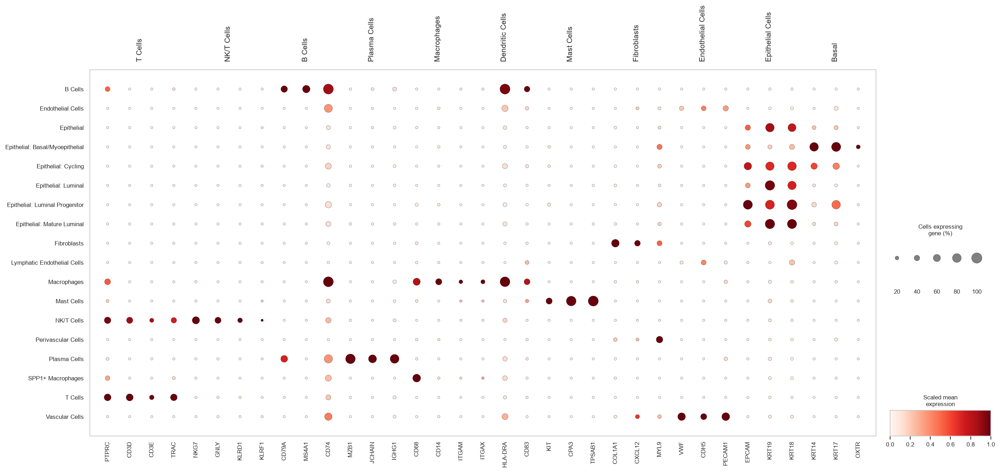

In [170]:
marker_dotplot = sc.pl.dotplot(
    adata, available, groupby="cl_annotation", layer="log1p",
    standard_scale="var", smallest_dot=10, figsize=[22, 9],
    return_fig=True, show=False,
)
marker_dotplot.legend(
    width=2.5, size_title="Cells expressing\ngene (%)",
    colorbar_title="Scaled mean\nexpression",
)
marker_dotplot.make_figure()
save_figure(marker_dotplot.fig, fig_dir / "dotplot_celltype_annotation_markers", close=False, overwrite=False)
plt.show()


In [171]:
epi = adata[adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")]
x = np.asarray(epi[:, "EPCAM"].layers["log1p"].todense()).ravel()
print(f"EPCAM detected in {100 * (x > 0).mean():.1f}% of the epithelial subset")


EPCAM detected in 48.2% of the epithelial subset


## Epithelial compartment

In [172]:
plot_order = ["N", "TN", "HER2+", "ER+"]
condition_rank = {condition: i for i, condition in enumerate(plot_order)}
plot_idx = adata.obs["condition"].map(condition_rank).sort_values().index


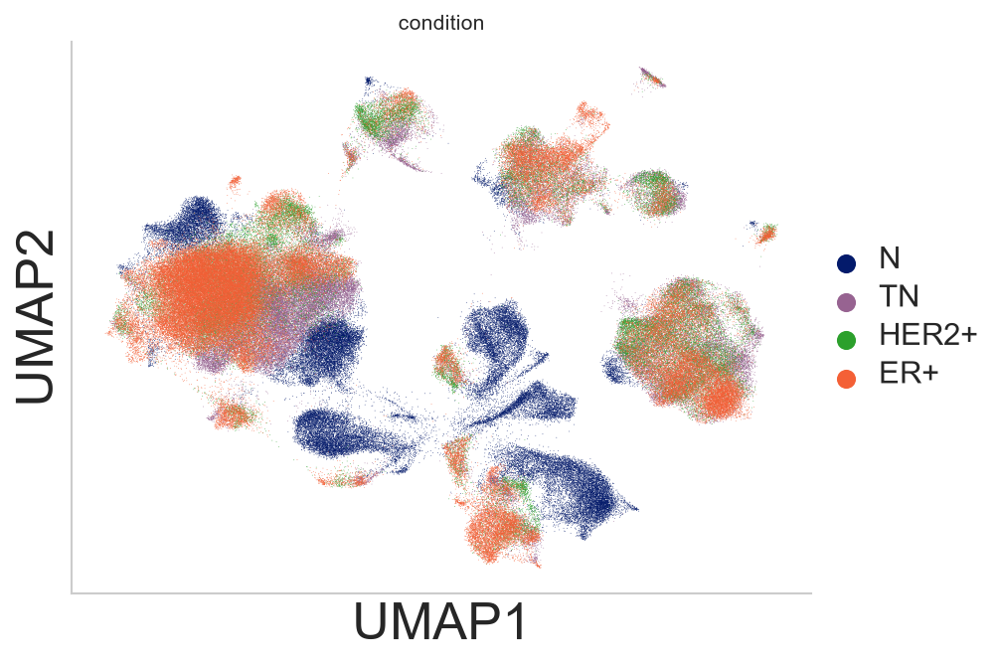

In [173]:
sc.pl.umap(
    adata[plot_idx],
    color="condition",
    palette=condition_palette,
    ncols=1,
    vmax="p99",
    show=False,
)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)
legend = ax.get_legend()
if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])
save_umap_figure(plt.gcf(), fig_dir / "umap_condition", close=False, overwrite=False)
plt.show()


In [174]:
celltype_categories = list(
    pd.Categorical(adata.obs["cl_annotation"]).categories.astype(str)
)
celltypes = sorted(set(celltype_categories))
colors = plt.get_cmap("tab20b").colors


In [175]:
assert len(celltypes) <= len(colors), "More cell types than tab20b colours"
celltype_palette = {label: to_hex(colors[i]) for i, label in enumerate(celltypes)}
adata.uns["cl_annotation_colors"] = [
    celltype_palette[label] for label in celltype_categories
]


In [176]:
missing = set(adata.obs["cl_annotation"].astype(str).unique()) - set(celltype_palette)
assert not missing, f"palette missing: {missing}"
pd.Series(celltype_palette, name="colour").rename_axis("cell_type").to_csv(
    df_dir / "celltype_palette.csv"
)


In [177]:
gc.collect()


29480

In [178]:
assert adata.obs["cl_annotation"].notna().all()


In [179]:
epithelial_mask = adata.obs["epithelial_primary"].astype(bool)


In [180]:
epithelial_obs = adata.obs.loc[
    epithelial_mask, ["sample", "condition", "cl_annotation", "scVI_leiden"]
].copy()


In [181]:
print(f"Epithelial cells: {epithelial_mask.sum():,}")


Epithelial cells: 123,382


In [182]:
print("\nCell types:")
print(epithelial_obs["cl_annotation"].value_counts())



Cell types:
cl_annotation
Epithelial: Mature Luminal         45458
Epithelial: Luminal                26061
Epithelial: Cycling                16188
Epithelial: Basal/Myoepithelial    12258
Epithelial                         12243
Epithelial: Luminal Progenitor     11174
Endothelial Cells                      0
B Cells                                0
Fibroblasts                            0
Lymphatic Endothelial Cells            0
Macrophages                            0
Mast Cells                             0
NK/T Cells                             0
Perivascular Cells                     0
Plasma Cells                           0
SPP1+ Macrophages                      0
T Cells                                0
Vascular Cells                         0
Name: count, dtype: int64


In [183]:
print("\nConditions:")
print(epithelial_obs["condition"].value_counts())



Conditions:
condition
ER+      54256
N        26363
TN       26248
HER2+    16515
Name: count, dtype: int64


In [184]:
print("\nSamples:")
print(epithelial_obs["sample"].value_counts())



Samples:
sample
GSM4909282_TN-MH0135         12113
GSM4909306_ER-MH0029-9C       5803
GSM4909297_ER-MH0125          5462
GSM4909296_ER-MH0001          5064
GSM4909304_ER-MH0163          5060
GSM4909307_ER-MH0040          4991
GSM4909294_HER2-MH0176        4985
GSM4909286_TN-B1-MH0131       4846
GSM4909315_ER-MH0167-T        4820
GSM4909285_TN-B1-MH4031       4706
GSM4909270_N-PM0342-Total     4366
GSM4909268_N-MH0023-Total     4055
GSM4909293_HER2-MH0161        3847
GSM4909254_N-PM0019-Total     3826
GSM4909302_ER-MH0025          3673
GSM4909253_N-PM0092-Total     3164
GSM4909289_HER2-AH0308        3013
GSM4909290_HER2-PM0337        2981
GSM4909313_ER-MH0064-T        2932
GSM4909311_ER-MH0056-T        2908
GSM4909301_ER-MH0042          2701
GSM4909287_TN-B1-Tum0554      2626
GSM4909317_ER-MH0173-T        2602
GSM4909309_ER-MH0043-T        2582
GSM4909257_N-PM0095-Total     2187
GSM4909265_N-PM0233-Total     2044
GSM4909305_ER-MH0029-7C       2034
GSM4909298_ER-PM0360          1852
GSM

In [185]:
if run_reference_annotation:
    pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"]).to_csv(
        df_dir / "cluster_vs_celltypist.csv"
    )


## Atlas composition

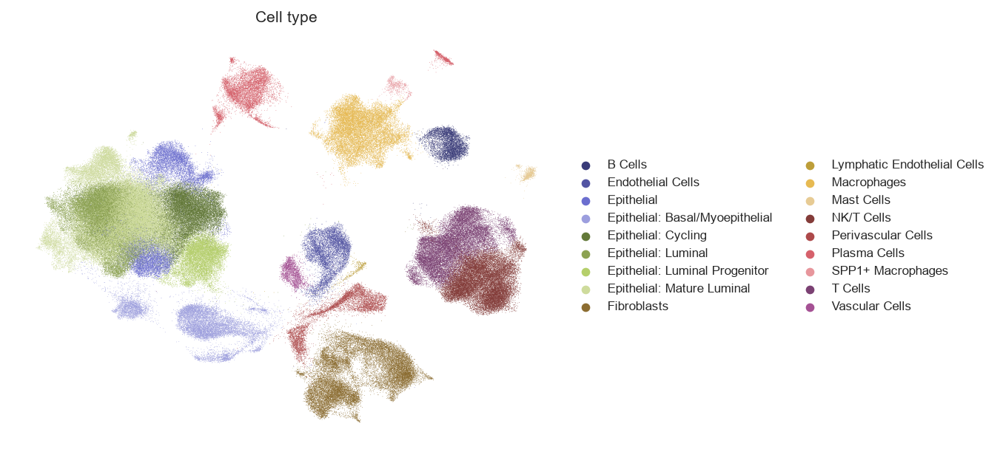

In [186]:
sc.pl.umap(
    adata,
    color="cl_annotation",
    palette=celltype_palette,
    legend_loc="right margin",
    legend_fontsize=8,
    frameon=False,
    title="Cell type",
    show=False,
)
save_umap_figure(plt.gcf(), fig_dir / "atlas_celltype_umap", close=False, overwrite=False)
plt.show()


In [187]:
comp = pd.crosstab(
    adata.obs["sample_short"], adata.obs["cl_annotation"], normalize="index"
)


In [188]:
order = (
    adata.obs[["sample_short", "condition"]]
    .drop_duplicates()
    .assign(rank=lambda d: d["condition"].map({"N": 0, "TN": 1, "HER2+": 2, "ER+": 3}))
    .sort_values(["rank", "sample_short"])["sample_short"]
)
comp = comp.loc[order]


In [189]:
cols = [c for c in celltype_palette if c in comp.columns] + [
    c for c in comp.columns if c not in celltype_palette
]
comp = comp[cols]


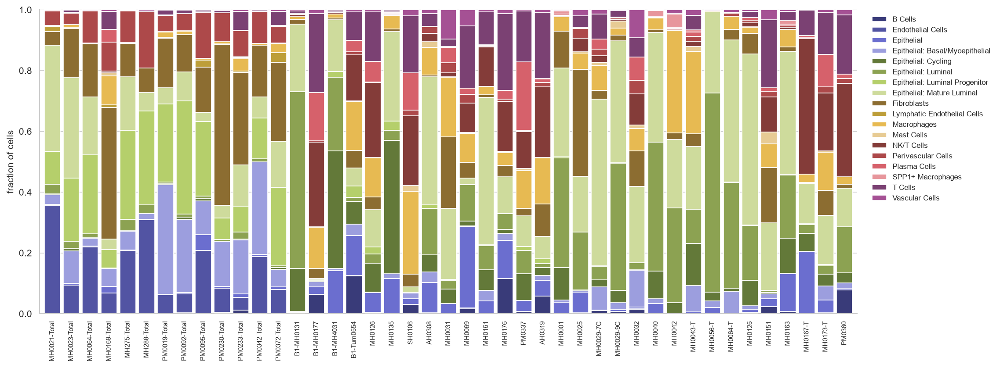

In [190]:
fig, ax = plt.subplots(figsize=(16, 6))
comp.plot(
    kind="bar",
    stacked=True,
    width=0.85,
    ax=ax,
    color=[celltype_palette.get(c, "lightgrey") for c in comp.columns],
)
ax.set_xlabel("")
ax.set_ylabel("fraction of cells")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, fig_dir / "atlas_celltype_composition_by_sample", close=False, overwrite=False)
plt.show()


In [191]:
comp.to_csv(df_dir / "celltype_fraction_per_sample.csv")


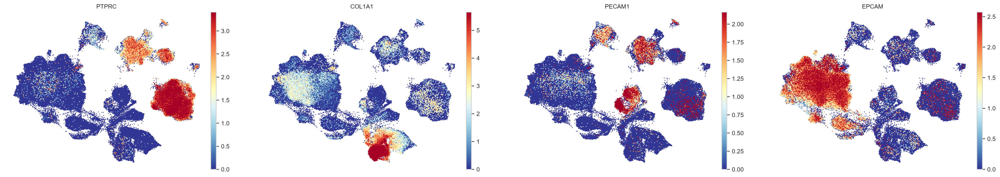

In [192]:
sc.pl.umap(
    adata,
    color=["PTPRC", "COL1A1", "PECAM1", "EPCAM"],
    ncols=4,
    layer="log1p",
    cmap="RdYlBu_r",
    vmin=0,
    vmax="p99",
    size=8,
    frameon=False,
    show=False,
)
save_umap_figure(plt.gcf(), fig_dir / "atlas_lineage_marker_umaps", close=False, overwrite=False)
plt.show()


In [193]:
genes_present = [
    g
    for g in sorted({g for v in marker_genes.values() for g in v})
    if g in adata.var_names
]


In [194]:
adata_sub = adata[:, genes_present].copy()
x_matrix = adata_sub.layers["log1p"]


In [195]:
df = pd.DataFrame(
    x_matrix.toarray() if hasattr(x_matrix, "toarray") else x_matrix,
    index=adata_sub.obs_names,
    columns=genes_present,
)
df["cluster"] = adata_sub.obs["scVI_leiden"].values
df["cell_type"] = adata_sub.obs["cl_annotation"].values


In [196]:
df.index.name = "barcode"
tmp = df.reset_index()


In [197]:
long_df = tmp.melt(
    id_vars=["barcode", "cluster", "cell_type"],
    var_name="gene",
    value_name="expression",
)


In [198]:
long_df.to_csv(df_dir / "dotplot_long_format.csv", index=False)


In [199]:
del adata_sub
gc.collect()


20691

## Save annotated cells

In [200]:
def _atomic_h5ad(adata, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp.h5ad")
    adata.write_h5ad(temporary, compression="gzip")
    os.replace(temporary, path)


In [201]:
if "epi" in globals():
    del epi
gc.collect()


204

In [202]:
if getattr(adata, "isbacked", False):
        raise ValueError("Use the in-memory atlas for this export; no training is needed")


In [203]:
assert adata.obs["cl_annotation"].notna().all()
assert adata.uns["annotation_mapping"]["method"] == "manual"


In [204]:
save_dir.mkdir(parents=True, exist_ok=True)


In [205]:
_atomic_h5ad(adata, save_dir / "project_annotated.h5ad")


In [206]:
epi = adata[adata.obs.epithelial_primary.to_numpy(bool)].copy()
assert epi.obs["epithelial_primary"].all()


In [207]:
_atomic_h5ad(epi, save_dir / "epithelial.h5ad")


In [208]:
receipt = {"method": "manual", "n_atlas": adata.n_obs, "n_epithelial": epi.n_obs}
receipt.update(atlas_file="project_annotated.h5ad", primary_file="epithelial.h5ad", status="complete")


In [209]:
(df_dir / "epithelial_identity_completion.json").write_text(
        json.dumps(receipt, indent=2) + "\n")


175

In [210]:
print("primary epithelial:", epi.shape)


primary epithelial: (123382, 28502)


## Epithelial sample contribution

In [211]:
contrib = (
    epi.obs.groupby(["condition", "sample_short"], observed=True)
    .size().rename("cells").reset_index())
contrib["rank"] = contrib["condition"].map(condition_rank)
contrib = contrib.sort_values(["rank", "cells"], ascending=[True, False])


In [212]:
inner = (
    contrib.groupby("condition", observed=True)["cells"]
    .sum()
    .reindex([c for c in condition_order if c in set(contrib["condition"])])
)
inner_colors = [
    condition_palette.get(c, condition_palette.get(c.rstrip("+"), "lightgrey"))
    for c in inner.index
]
outer_colors = []


In [213]:
for c, col in zip(inner.index, inner_colors):
    n = int((contrib["condition"] == c).sum())
    outer_colors += [to_rgba(col, alpha=a) for a in np.linspace(0.95, 0.35, n)]


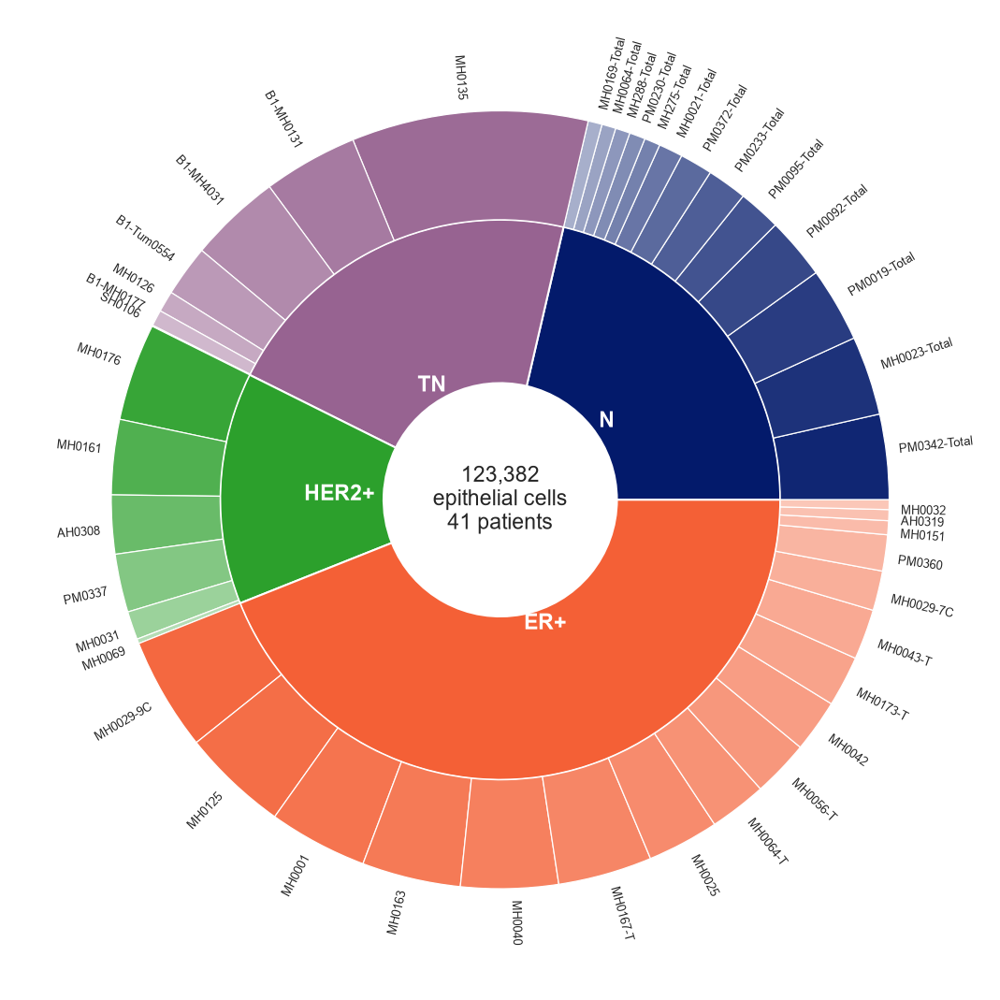

In [214]:
fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(inner.values,
    radius=0.72,
    colors=inner_colors,
    labels=inner.index,
    labeldistance=0.45,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1),
    textprops=dict(fontsize=11, weight="bold", color="white"),
)
ax.pie(contrib["cells"].values,
    radius=1.0,
    colors=outer_colors,
    labels=contrib["sample_short"],
    labeldistance=1.03,
    rotatelabels=True,
    wedgeprops=dict(width=0.28, edgecolor="white", linewidth=0.6),
    textprops=dict(fontsize=6),
)
ax.set(aspect="equal")
ax.text(
    0,
    0,
    f"{epi.n_obs:,}\nepithelial cells\n{epi.obs['patient'].nunique()} patients",
    ha="center",
    va="center",
    fontsize=11,
)
save_figure(fig, fig_dir / "epithelial_contribution_by_sample", close=False, overwrite=False)
plt.show()


In [215]:
contrib.to_csv(df_dir / "epithelial_contribution_per_sample.csv", index=False)


In [216]:
epi_mask = adata.obs["epithelial_primary"].astype(bool)
x = np.asarray(adata[:, "EPCAM"].layers["log1p"].todense()).ravel() > 0


In [217]:
print(f"EPCAM+ inside  epithelial : {100 * x[epi_mask].mean():.1f}%")
print(f"EPCAM+ outside epithelial : {100 * x[~epi_mask].mean():.1f}%")


EPCAM+ inside  epithelial : 48.2%
EPCAM+ outside epithelial : 1.8%


## Integration diagnostics within cell types

In [218]:
def broad_lineages(labels):
    """Avoid assessing mixing separately within arbitrary epithelial subtypes."""
    labels = labels.astype(str).copy()
    labels.loc[labels.str.startswith("Epithelial")] = "Epithelial"
    labels.loc[labels.isin(["T Cells", "NK Cells", "T/NK Cells"])] = "T/NK compartment"
    return labels


In [219]:
def conditional_neighbour_mixing(
    obs, graph, annotation_key="cl_annotation", block_size=4096, collapse_lineages=True
):
    """Compare sample/donor neighbours within the same lineage AND condition.

    Expected same-unit probability excludes the focal cell. The expectation is
    a composition reference, not a calibrated null model or significance test.
    """
    required = [annotation_key, "condition", "sample", "patient"]
    if obs[required].isna().any().any():
        raise ValueError(
            "Complete annotation, condition, sample and patient metadata required"
        )
    if not obs.index.is_unique or graph.shape != (len(obs), len(obs)):
        raise ValueError("Graph must match unique metadata rows")
    if (
        (obs.groupby("sample", observed=True)[["patient", "condition"]].nunique() > 1)
        .any()
        .any()
    ):
        raise ValueError("A sample maps to multiple patients or conditions")
    frame = obs[required].copy()
    frame["lineage"] = (
        broad_lineages(frame[annotation_key])
        if collapse_lineages
        else frame[annotation_key].astype(str)
    )
    strata = ["lineage", "condition"]
    stratum_codes = pd.factorize(pd.MultiIndex.from_frame(frame[strata]))[0]
    group_n = (
        frame.groupby(strata, observed=True)["sample"].transform("size").to_numpy()
    )
    frame["n_cells_in_stratum"] = group_n
    sample_codes = pd.factorize(frame["sample"])[0]
    patient_codes = pd.factorize(frame["patient"])[0]
    g = graph.tocsr(copy=True)
    g.setdiag(0)
    g.eliminate_zeros()
    degree = np.zeros(len(frame), dtype=np.int64)
    same = {"sample": np.zeros(len(frame)), "patient": np.zeros(len(frame))}
    for start in range(0, len(frame), block_size):
        stop = min(start + block_size, len(frame))
        lo, hi = (g.indptr[start], g.indptr[stop])
        targets = g.indices[lo:hi]
        rows = np.repeat(np.arange(start, stop), np.diff(g.indptr[start : stop + 1]))
        valid = stratum_codes[rows] == stratum_codes[targets]
        rows, targets = (rows[valid], targets[valid])
        degree[start:stop] = np.bincount(rows - start, minlength=stop - start)
        for name, codes in [("sample", sample_codes), ("patient", patient_codes)]:
            same[name][start:stop] = np.bincount(
                rows - start,
                weights=codes[rows] == codes[targets],
                minlength=stop - start,
            )
    frame["n_eligible_neighbours"] = degree
    for name in ["sample", "patient"]:
        unit_n = (
            frame.groupby(strata + [name], observed=True)[name]
            .transform("size")
            .to_numpy()
        )
        n_units = (
            frame.groupby(strata, observed=True)[name].transform("nunique").to_numpy()
        )
        observed = np.divide(
            same[name], degree, out=np.full(len(frame), np.nan), where=degree > 0
        )
        expected = np.divide(
            unit_n - 1, group_n - 1, out=np.full(len(frame), np.nan), where=group_n > 1
        )
        frame[f"n_{name}s_in_stratum"] = n_units
        frame[f"observed_same_{name}"] = observed
        frame[f"expected_same_{name}"] = expected
        frame[f"excess_same_{name}"] = observed - expected
        frame[f"informative_{name}"] = (n_units > 1) & (degree >= 5)
    return frame


In [220]:
if "X_scVI" not in adata.obsm or "connectivities" not in adata.obsp:
    raise ValueError("Run scVI and neighbours before these diagnostics")


In [221]:
integration_out = Path(df_dir / "integration_diagnostics")
integration_out.mkdir(parents=True, exist_ok=True)


In [222]:
integration_obs = adata.obs.copy()
if "cl_annotation" not in integration_obs:
    raise ValueError("Review cluster annotation before within-lineage mixing checks")
integration_obs["lineage"] = broad_lineages(integration_obs["cl_annotation"])


In [223]:
integration_units = integration_obs[
    ["sample", "patient", "condition"]
].drop_duplicates()


In [224]:
integration_units.to_csv(integration_out / "analysis_units.csv", index=False)


In [225]:
for integration_key in ["sample", "patient", "condition"]:
    integration_counts = pd.crosstab(
        integration_obs["lineage"], integration_obs[integration_key]
    )
    integration_counts.to_csv(
        integration_out / f"lineage_by_{integration_key}_counts.csv"
    )
    integration_counts.div(integration_counts.sum(axis=1), axis=0).to_csv(
        integration_out / f"lineage_by_{integration_key}_fractions.csv"
    )


In [226]:
integration_mixing = conditional_neighbour_mixing(
    integration_obs, adata.obsp["connectivities"], "cl_annotation"
)


In [227]:
for integration_unit in ["sample", "patient"]:
    for integration_metric in ["observed", "excess"]:
        integration_column = f"{integration_metric}_same_{integration_unit}"
        integration_mixing[integration_column] = integration_mixing[
            integration_column
        ].where(integration_mixing[f"informative_{integration_unit}"])


In [228]:
integration_per_library = integration_mixing.groupby(
    ["lineage", "condition", "sample", "patient"], observed=True
).agg(
    n_cells=("sample", "size"),
    median_eligible_neighbours=("n_eligible_neighbours", "median"),
    n_samples_in_stratum=("n_samples_in_stratum", "first"),
    n_patients_in_stratum=("n_patients_in_stratum", "first"),
    median_same_sample=("observed_same_sample", "median"),
    expected_same_sample=("expected_same_sample", "first"),
    median_excess_same_sample=("excess_same_sample", "median"),
    median_same_patient=("observed_same_patient", "median"),
    expected_same_patient=("expected_same_patient", "first"),
    median_excess_same_patient=("excess_same_patient", "median"),
    fraction_informative_sample=("informative_sample", "mean"),
)


In [229]:
integration_per_library.to_csv(integration_out / "conditional_mixing_by_library.csv")


In [230]:
integration_balanced = (
    integration_per_library.reset_index()
    .groupby(["lineage", "condition"], observed=True)
    .agg(
        n_libraries=("sample", "nunique"),
        n_patients=("patient", "nunique"),
        median_library_excess_same_sample=("median_excess_same_sample", "median"),
        median_library_excess_same_patient=("median_excess_same_patient", "median"),
        median_eligible_neighbours=("median_eligible_neighbours", "median"),
    )
)


In [231]:
integration_balanced.to_csv(integration_out / "conditional_mixing_summary.csv")


In [232]:
integration_subtype = conditional_neighbour_mixing(
    integration_obs,
    adata.obsp["connectivities"],
    "cl_annotation",
    collapse_lineages=False,
)


In [233]:
for integration_unit in ["sample", "patient"]:
    integration_subtype[f"excess_same_{integration_unit}"] = integration_subtype[
        f"excess_same_{integration_unit}"
    ].where(integration_subtype[f"informative_{integration_unit}"])


In [234]:
integration_subtype_library = integration_subtype.groupby(
    ["lineage", "condition", "sample", "patient"], observed=True
).agg(
    n_cells=("sample", "size"),
    median_excess_same_sample=("excess_same_sample", "median"),
    median_excess_same_patient=("excess_same_patient", "median"),
    fraction_informative_sample=("informative_sample", "mean"),
)


In [235]:
integration_subtype_library.to_csv(
    integration_out / "annotated_subtype_mixing_by_library.csv"
)


In [236]:
integration_subtype_summary = (
    integration_subtype_library.reset_index()
    .groupby(["lineage", "condition"], observed=True)
    .agg(
        n_libraries=("sample", "nunique"),
        n_patients=("patient", "nunique"),
        median_library_excess_same_sample=("median_excess_same_sample", "median"),
        median_library_excess_same_patient=("median_excess_same_patient", "median"),
    )
)


In [237]:
integration_subtype_summary.to_csv(
    integration_out / "annotated_subtype_mixing_summary.csv"
)


In [238]:
integration_latent = np.asarray(adata.obsm["X_scVI"])
integration_latent_columns = [
    f"latent_{integration_j + 1}"
    for integration_j in range(integration_latent.shape[1])
]


In [239]:
integration_qc_columns = [
    integration_c
    for integration_c in [
        "total_counts",
        "n_genes_by_counts",
        "pct_counts_mt",
        "pct_counts_ribo",
        "doublet_score",
        "S_score",
        "G2M_score",
    ]
    if integration_c in integration_obs
]


In [240]:
integration_groups = [("All cells", "All", np.arange(len(integration_obs)))]
integration_groups += [
    (str(integration_key[0]), str(integration_key[1]), integration_idx)
    for integration_key, integration_idx in integration_obs.groupby(
        ["lineage", "condition"], observed=True
    ).indices.items()
    if len(integration_idx) >= 200
]


In [241]:
integration_rng = np.random.default_rng(0)


In [242]:
integration_correlations = []


In [243]:
for (
    integration_lineage,
    integration_condition,
    integration_indices,
) in integration_groups:
    integration_indices = np.asarray(integration_indices)
    integration_selected = (
        np.sort(integration_rng.choice(integration_indices, size=5000, replace=False))
        if len(integration_indices) > 5000
        else integration_indices
    )
    integration_data = pd.DataFrame(
        integration_latent[integration_selected], columns=integration_latent_columns
    )
    for integration_column in integration_qc_columns:
        integration_data[integration_column] = integration_obs.iloc[
            integration_selected
        ][integration_column].to_numpy()
    integration_corr = integration_data.corr(method="spearman").loc[
        integration_latent_columns, integration_qc_columns
    ]
    for integration_dim in integration_latent_columns:
        for integration_column in integration_qc_columns:
            integration_correlations.append(
                {
                    "lineage": integration_lineage,
                    "condition": integration_condition,
                    "latent_dimension": integration_dim,
                    "covariate": integration_column,
                    "spearman_r": integration_corr.loc[
                        integration_dim, integration_column
                    ],
                    "n_cells_total": len(integration_indices),
                    "n_cells_evaluated": len(integration_selected),
                }
            )


In [244]:
integration_correlations = pd.DataFrame(integration_correlations)


In [245]:
integration_correlations.to_csv(
    integration_out / "latent_qc_correlations.csv", index=False
)


In [246]:
integration_cell_hash = hashlib.sha256(
    pd.util.hash_pandas_object(
        integration_obs[["cl_annotation", "sample", "patient", "condition"]], index=True
    )
    .to_numpy()
    .tobytes()
).hexdigest()


In [247]:
(integration_out / "provenance.json").write_text(
    json.dumps(
        {
            "seed": 0,
            "annotation_key": "cl_annotation",
            "cell_metadata_sha256": integration_cell_hash,
            "n_cells": len(integration_obs),
            "n_latent": integration_latent.shape[1],
            "scope": "Descriptive post-training diagnostics; no model or annotation changes",
        },
        indent=2,
    )
)


269

In [248]:
integration_review = {
    "mixing_by_library": integration_per_library,
    "mixing_summary": integration_balanced,
    "annotated_subtype_summary": integration_subtype_summary,
    "latent_qc_correlations": integration_correlations,
}
display(integration_review["annotated_subtype_summary"].round(3))


n_libraries  n_patients  \
lineage           condition                            
B Cells           N                   10          10   
                  TN                   7           7   
                  HER2+                6           6   
                  ER+                 15          14   
Endothelial Cells N                   13          13   
...                                  ...         ...   
T Cells           ER+                 16          15   
Vascular Cells    N                   12          12   
                  TN                   7           7   
                  HER2+                6           6   
                  ER+                 17          16   

                             median_library_excess_same_sample  \
lineage           condition                                      
B Cells           N                                      0.058   
                  TN                                     0.124   
                  HER2+                                 -0.003   
                  ER+                                    0.132   
Endothelial Cells N                                      0.206   
...                                                        ...   
T Cells           ER+                                    0.243   
Vascular Cells    N                                      0.050   
                  TN                                     0.166   
                  HER2+                                  0.231   
                  ER+                                    0.108   

                             median_library_excess_same_patient  
lineage           condition                                      
B Cells           N                                       0.058  
                  TN                                      0.124  
                  HER2+                                  -0.003  
                  ER+                                     0.126  
Endothelial Cells N                                       0.206  
...                                                         ...  
T Cells           ER+                                     0.243  
Vascular Cells    N                                       0.050  
                  TN                                      0.166  
                  HER2+                                   0.231  
                  ER+                                     0.108  

[69 rows x 4 columns]

In [249]:
session_info.show()
